# Lesion Segmentation — Mobile-UNet v5 (EfficientNetB0 pretrained encoder)

**This version drops the "no transfer learning" constraint** that every earlier notebook
in this series stated and audited for. The encoder is now `EfficientNetB0` pretrained on
ImageNet; the decoder (attention gates, CBAM, ASPP, deep supervision) is the same custom
code as before. If this is for a report that claims no transfer learning, that claim no
longer holds for this notebook specifically — say so explicitly wherever these numbers
get reported.

## Why this should help

Every prior run in this series trained a Mobile-UNet from scratch on ~1,800 images. A
from-scratch encoder has to learn "what an edge looks like" and "what texture separates
tissue from lesion" from that same small dataset — the encoder and the segmentation task
are fighting for the same limited signal. EfficientNetB0's encoder already knows a very
general visual vocabulary (edges, textures, color gradients) from 1.3M ImageNet images
before it ever sees your data, so the ~1,800 lesion images only need to teach it what's
*specific* to oral lesions, not vision from zero.

## Architecture: EfficientNetB0 encoder + custom decoder

- Skip connections pulled from four standard EfficientNetB0 stage-boundary layers
  (`block2a_expand_activation`, `block3a_expand_activation`, `block4a_expand_activation`,
  `block6a_expand_activation`) at resolutions 128/64/32/16 for a 256px input, plus
  `top_activation` (8×8×1280) as the bottleneck. These are the layer names the
  segmentation community has used for EfficientNet-UNet skip connections for years —
  verified against a live model build before writing this notebook, not guessed.
- Bottleneck: ASPP (dilated multi-scale context) + CBAM, same as your `mu_d_deepsup` run.
- Decoder: attention-gated skip fusion + residual separable blocks, same code as before.
- Deep supervision aux heads at 128×128 and 64×64 (matching `IMG_SIZE//2` and
  `IMG_SIZE//4`, exactly what the existing augmentation pipeline's targets already are).
- A small full-resolution "stem skip" (a couple of separable conv layers run directly on
  the raw input, in parallel with EfficientNet) is fused at the final decoder stage,
  because EfficientNet's stem downsamples immediately — there's no encoder feature at the
  input's native 256×256 resolution otherwise.
- Total: ~6.4M params (≈4.05M pretrained encoder + ≈2.35M decoder) — bigger than your
  1.2–1.5M custom Mobile-UNet, still far smaller than a ResNet50-backed segmentation model
  (25M+), reported the same way as every prior run (Section 15).

## Training: two phases, one kernel session

1. **Phase 1 — encoder frozen** (~15 epochs): only the decoder trains, against stable
   pretrained features, at a normal LR. Prevents the decoder's early, noisy gradients
   from wrecking useful pretrained weights.
2. **Phase 2 — encoder unfrozen, fine-tuned** (~35 epochs): the whole network trains
   together at a much lower LR (1/30th of phase 1), with BatchNorm layers inside the
   encoder kept frozen (their running statistics reflect ImageNet's distribution, which a
   handful of fine-tuning epochs on 1,800 images can't safely re-estimate).

Both phases run in this one notebook, one after another, no restart.

## Also carried over from the last diagnosis

Your last run (custom architecture, all four fixed training-recipe changes stacked)
underfit — train Dice dropped from ~0.71 to ~0.58 because oversampling starved large
lesions and elastic+cutout+crop stacked together made every example harder to fit in the
epoch budget. This run uses the toned-down settings from that diagnosis: oversampling
target frequencies closer to natural, lower elastic/cutout/crop probabilities, lower
weight decay and dropout, longer patience. See Section 2 for the exact numbers.

## Kaggle memory/disk notes

- `BATCH_SIZE` is lower than your custom-architecture runs (EfficientNetB0 + decoder uses
  more activation memory than the ~1.5M-param custom model did) — reduce further if you
  hit `ResourceExhaustedError`; the notebook prints the exact fallback.
- SWA runs only over phase 2's last checkpoints (averaging across the frozen→unfrozen
  transition would average two different training regimes together, which doesn't mean
  anything) and deletes its checkpoint pool from `/kaggle/working` right after.
- `weights="imagenet"` downloads ~16MB of pretrained weights the first time EfficientNetB0
  is built in a fresh Kaggle session — this needs internet access enabled on the kernel
  (Settings → Internet → On). If it's off, the download will fail before training starts.


In [1]:
# ============================================================
# 1. ENVIRONMENT / GPU
# ============================================================
import os
import sys
import json
import time
import math
import random
import warnings
from pathlib import Path
from collections import Counter

os.environ.setdefault("OPENCV_IO_ENABLE_JASPER", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models

warnings.filterwarnings("ignore", category=UserWarning)
try:
    cv2.setLogLevel(0)          # silence "Premature end of JPEG file" (OpenCV 4.x)
except AttributeError:
    try:
        cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_SILENT)
    except Exception:
        pass

print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("Keras      :", tf.keras.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPUs found :", len(gpus))

if not gpus:
    raise RuntimeError("STOP: No GPU visible. Do not start the 50-epoch run on CPU.")

try:
    tf.config.set_visible_devices(gpus[0], "GPU")
except Exception as e:
    print("Device-pin note:", e)

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("Memory-growth note:", e)

print("Using GPU  :", tf.config.get_visible_devices("GPU"))

from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy("mixed_float16")
print("Mixed precision policy:", mixed_precision.global_policy())

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("Environment: OK")


Python     : 3.12.13
TensorFlow : 2.20.0
Keras      : 3.13.2
GPUs found : 2
Using GPU  : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">
Environment: OK


In [2]:
# ============================================================
# 2. CONFIGURATION -- EfficientNetB0 encoder, two-phase training
# ============================================================

RUN_LABEL = "v5_effnetb0"

# ---- Backbone -------------------------------------------------
BACKBONE = "efficientnetb0"
IMG_SIZE = 256
BATCH_SIZE = 8          # lower than the custom-arch runs -- EfficientNetB0 + decoder
                        # uses more activation memory than the ~1.5M-param model did
GRAD_ACCUM_STEPS = 1
ACTIVATION = "swish"

# Decoder feature toggles (same meaning as every prior notebook in this series)
USE_GATES    = True
USE_CBAM     = True
USE_ASPP     = True
USE_DEEP_SUP = True

RUN_VARIANT_SELF_TEST = False   # single architecture, nothing to probe-build

assert IMG_SIZE % 32 == 0, "EfficientNetB0's 5 stride-2 stages need IMG_SIZE divisible by 32"

# ---- Two-phase training -----------------------------------------
PHASE1_EPOCHS = 15      # encoder frozen -- decoder-only warm-up
PHASE2_EPOCHS = 35      # encoder unfrozen -- whole-network fine-tune
TOTAL_EPOCHS  = PHASE1_EPOCHS + PHASE2_EPOCHS

PHASE1_LR = 3e-4        # normal LR -- only the decoder is moving
PHASE2_LR = 1e-5        # ~1/30th -- fine-tuning pretrained weights needs a small step
PHASE1_WARMUP_EPOCHS = 2
PHASE2_WARMUP_EPOCHS = 1
EARLY_STOP_PATIENCE = 20   # raised from 14 -- see the intro's "also carried over" note

# ---- Regularization (toned down from the run that showed underfitting) ----
WEIGHT_DECAY = 1.5e-5   # was pushed to 3e-5 last run; train/val gap there was already
                        # small (0.033), so there's room to regularize less
DROPOUT      = 0.10     # was 0.12
GLOBAL_CLIPNORM = 1.0
CBAM_REDUCTION  = 8
ASPP_MAX_FILTERS = 192

# ---- SWA (phase 2 only -- see intro) ------------------------------
SWA_LAST_N_EPOCHS  = 6
SWA_BN_RECAL_STEPS = 80

# ---- Loss --------------------------------------------------
TVERSKY_ALPHA  = 0.3
TVERSKY_BETA   = 0.7
TVERSKY_GAMMA  = 0.75
BCE_WEIGHT     = 0.5
TVERSKY_WEIGHT = 0.5
DEEP_SUP_WEIGHTS = {"head_out": 1.0, "aux_out_2": 0.4, "aux_out_4": 0.2}

# ---- Paths -------------------------------------------------
DATASET_DIR = Path("/kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project")
ANNOTATION_FILE = Path("/kaggle/input/datasets/annapoornaak/metadata-zenodo/Annotation.json")
OUTPUT_ROOT = Path("/kaggle/working/Segmentation Output")

RUN_DIR      = OUTPUT_ROOT / f"run_{RUN_LABEL}"
MASKS_DIR    = OUTPUT_ROOT / "lesion_masks_shared"
ABLATION_CSV = OUTPUT_ROOT / "ablation_results.csv"
ABLATION_ARM = RUN_LABEL   # kept under this name so the shared logging cell (Section 23)
                           # needs no further changes

for d in (OUTPUT_ROOT, RUN_DIR, MASKS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Data --------------------------------------------------
INCLUDE_NEGATIVES = False
LETTERBOX_RESIZE  = True
VAL_FRACTION      = 0.20

# ---- Lesion crop (Section 8) -- scale-consistent windowing, not zoom -------
USE_CROP = True
TRAIN_CROP_PROB     = 0.35   # was 0.50 -- toned down, see intro
CROP_MARGIN_LOW     = 1.30
CROP_MARGIN_HIGH    = 2.30

# ---- Oversampling by lesion-size bin (Section 8b) --------------------------
USE_OVERSAMPLE = True
SIZE_BIN_EDGES  = [0.0, 0.01, 0.05, 0.15, 1.0]
SIZE_BIN_LABELS = ["<1%", "1-5%", "5-15%", ">15%"]
# Closer to natural frequency than last run's 0.35/0.30/0.20/0.15 -- that
# combination starved >15% lesions of training exposure (0.781 -> 0.715).
SIZE_BIN_TARGET_FREQ = {"<1%": 0.28, "1-5%": 0.27, "5-15%": 0.23, ">15%": 0.22}

# ---- Elastic deform (Section 9) --------------------------------------------
USE_ELASTIC = True
ELASTIC_PROB         = 0.15   # was 0.30
ELASTIC_ALPHA_RANGE  = (8.0, 20.0)
ELASTIC_SIGMA_RANGE  = (4.0, 7.0)

# ---- Cutout (Section 9) -- mask-aware, fixed version -----------------------
USE_CUTOUT = True
CUTOUT_PROB          = 0.15   # was 0.30
CUTOUT_FRAC_RANGE    = (0.08, 0.20)
CUTOUT_NUM_CANDIDATES = 4
CUTOUT_MAX_LESION_OVERLAP = 0.15

USE_SWA = True
THRESHOLD_GRID = np.round(np.arange(0.10, 0.91, 0.05), 2)

print("=" * 70)
print("ENCODER  : EfficientNetB0, ImageNet-pretrained  (TRANSFER LEARNING: YES)")
print("DECODER  : custom Mobile-UNet decoder (gates/CBAM/ASPP/deep-sup, same as before)")
print("=" * 70)
print("Run label         :", RUN_LABEL)
print("img_size          :", IMG_SIZE, " batch:", BATCH_SIZE, "x", GRAD_ACCUM_STEPS)
print("Phase 1 (frozen)  :", PHASE1_EPOCHS, "epochs @ LR", PHASE1_LR)
print("Phase 2 (fine-tune):", PHASE2_EPOCHS, "epochs @ LR", PHASE2_LR)
print("weight_decay      :", WEIGHT_DECAY, " dropout:", DROPOUT)
print("use_crop          :", USE_CROP, " prob:", TRAIN_CROP_PROB, "(scale-consistent)")
print("use_oversample    :", USE_OVERSAMPLE, SIZE_BIN_TARGET_FREQ)
print("use_elastic       :", USE_ELASTIC, " prob:", ELASTIC_PROB)
print("use_cutout        :", USE_CUTOUT, " prob:", CUTOUT_PROB, "(mask-aware)")
print("use_swa           :", USE_SWA, "(phase 2 only)")
print("Run dir           :", RUN_DIR)
print("Results log       :", ABLATION_CSV)
print("=" * 70)


ENCODER  : EfficientNetB0, ImageNet-pretrained  (TRANSFER LEARNING: YES)
DECODER  : custom Mobile-UNet decoder (gates/CBAM/ASPP/deep-sup, same as before)
Run label         : v5_effnetb0
img_size          : 256  batch: 8 x 1
Phase 1 (frozen)  : 15 epochs @ LR 0.0003
Phase 2 (fine-tune): 35 epochs @ LR 1e-05
weight_decay      : 1.5e-05  dropout: 0.1
use_crop          : True  prob: 0.35 (scale-consistent)
use_oversample    : True {'<1%': 0.28, '1-5%': 0.27, '5-15%': 0.23, '>15%': 0.22}
use_elastic       : True  prob: 0.15
use_cutout        : True  prob: 0.15 (mask-aware)
use_swa           : True (phase 2 only)
Run dir           : /kaggle/working/Segmentation Output/run_v5_effnetb0
Results log       : /kaggle/working/Segmentation Output/ablation_results.csv


In [3]:
# ============================================================
# 3. LOAD + CHECK COCO JSON
# ============================================================
assert DATASET_DIR.exists(), f"STOP: dataset dir not found: {DATASET_DIR}"
assert ANNOTATION_FILE.exists(), f"STOP: annotation file not found: {ANNOTATION_FILE}"

with open(ANNOTATION_FILE, "r") as f:
    coco = json.load(f)

assert {"images", "annotations", "categories"}.issubset(coco.keys())

name_to_id = {c["name"]: c["id"] for c in coco["categories"]}
assert "Lesion" in name_to_id, f"No 'Lesion' category. Found: {list(name_to_id)}"

CAT_LESION = name_to_id["Lesion"]
CAT_ORAL = name_to_id.get("Oral Cavity")

cat_counts = Counter(a["category_id"] for a in coco["annotations"])

EXPECTED = {"images": 3000, "annotations": 6358, "lesion": 3358, "oral": 3000}
observed = {
    "images": len(coco["images"]),
    "annotations": len(coco["annotations"]),
    "lesion": cat_counts[CAT_LESION],
    "oral": cat_counts.get(CAT_ORAL, 0),
}

print(f"{'key':<14}{'v1 expected':>14}{'observed':>12}{'match':>8}")
for k in EXPECTED:
    print(f"{k:<14}{EXPECTED[k]:>14}{observed[k]:>12}"
          f"{('yes' if EXPECTED[k] == observed[k] else 'NO'):>8}")


key              v1 expected    observed   match
images                  3000        3000     yes
annotations             6358        6358     yes
lesion                  3358        3358     yes
oral                    3000        3000     yes


In [4]:
# ============================================================
# 4. IMAGE ID -> FILE PATH  +  LESION GROUPING
# ============================================================
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")

filename_to_path = {}
for p in DATASET_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
        filename_to_path.setdefault(p.name, p)

images_info = {img["id"]: img for img in coco["images"]}

image_id_to_path, unmatched = {}, []
for image_id, info in images_info.items():
    fname = Path(info["file_name"]).name
    if fname in filename_to_path:
        image_id_to_path[image_id] = filename_to_path[fname]
    else:
        unmatched.append((image_id, fname))

print("JSON images :", len(images_info))
print("Matched     :", len(image_id_to_path))
print("Unmatched   :", len(unmatched), unmatched[:3])

assert len(image_id_to_path) > 0, "STOP: no images matched."

lesion_by_image = {}
for ann in coco["annotations"]:
    if ann["category_id"] == CAT_LESION:
        lesion_by_image.setdefault(ann["image_id"], []).append(ann)

negative_ids = sorted(set(images_info) - set(lesion_by_image))

print("Images WITH lesion    :", len(lesion_by_image))
print("Images WITHOUT lesion :", len(negative_ids))


JSON images : 3000
Matched     : 3000
Unmatched   : 0 []
Images WITH lesion    : 2271
Images WITHOUT lesion : 729


In [5]:
# ============================================================
# 5. ROBUST IMAGE READER + MASK GENERATION
# ============================================================
def safe_imread(path, flags=cv2.IMREAD_COLOR):
    """Decode an image, tolerating truncated JPEG tails."""
    img = cv2.imread(str(path), flags)
    if img is not None:
        return img
    try:
        buf = np.fromfile(str(path), dtype=np.uint8)
        img = cv2.imdecode(buf, flags)
    except Exception:
        img = None
    return img


def lesion_polygons(image_id):
    """Raw (unclipped) polygon list for an image -- used both for mask
    rendering and for bbox computation in the crop-training pipeline."""
    polys = []
    for ann in lesion_by_image.get(image_id, []):
        seg = ann.get("segmentation", [])
        if not seg:
            continue
        polygons = [seg] if isinstance(seg[0], (int, float)) else seg
        for poly in polygons:
            if len(poly) < 6:
                continue
            polys.append(np.asarray(poly, dtype=np.float32).reshape(-1, 2))
    return polys


def create_lesion_mask(image_id):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        return None

    image = safe_imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        return None

    h, w = image.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)

    for pts in lesion_polygons(image_id):
        pts = np.round(pts).astype(np.int32)
        pts[:, 0] = np.clip(pts[:, 0], 0, w - 1)
        pts[:, 1] = np.clip(pts[:, 1], 0, h - 1)
        cv2.fillPoly(mask, [pts], 255)

    return mask


def lesion_bbox_frac(image_id, img_shape=None):
    """Lesion bounding box as (x0,y0,x1,y1) IN FRACTIONS of image width/height.
    Returns None if there is no lesion (crop training then falls back to the
    letterboxed full frame). img_shape lets us avoid re-reading the image
    when the caller already knows h,w."""
    polys = lesion_polygons(image_id)
    if not polys:
        return None
    if img_shape is None:
        image_path = image_id_to_path.get(image_id)
        image = safe_imread(image_path, cv2.IMREAD_COLOR)
        if image is None:
            return None
        h, w = image.shape[:2]
    else:
        h, w = img_shape
    all_pts = np.concatenate(polys, axis=0)
    x0, y0 = all_pts[:, 0].min(), all_pts[:, 1].min()
    x1, y1 = all_pts[:, 0].max(), all_pts[:, 1].max()
    return (float(x0 / w), float(y0 / h), float(x1 / w), float(y1 / h))


_m = create_lesion_mask(next(iter(lesion_by_image)))
assert _m is not None and _m.dtype == np.uint8
assert set(np.unique(_m)).issubset({0, 255}) and np.count_nonzero(_m) > 0
print("Mask unit test: PASS  shape =", _m.shape,
      " positive px =", int(np.count_nonzero(_m)))
del _m


Mask unit test: PASS  shape = (3456, 4608)  positive px = 141110


In [6]:
# ============================================================
# 5b. JPEG INTEGRITY SCAN (NEW)
#     "Premature end of JPEG file" fired on nearly every batch in the
#     previous run. This counts how many files are actually truncated. It
#     does NOT fix corrupted files -- it tells you how big the problem is.
# ============================================================
from PIL import Image as _PILImage

_scan_ids = sorted(image_id_to_path.keys())
_bad_files, _unreadable = [], []

for image_id in tqdm(_scan_ids, desc="JPEG integrity scan"):
    path = image_id_to_path[image_id]
    try:
        with _PILImage.open(path) as im:
            im.verify()          # raises if the file is truncated/corrupt
    except Exception as e:
        _bad_files.append((image_id, path.name, str(e)[:60]))

    img = safe_imread(path, cv2.IMREAD_COLOR)
    if img is None:
        _unreadable.append((image_id, path.name))

print("=" * 60)
print("JPEG INTEGRITY SCAN")
print("=" * 60)
print(f"Files scanned                 : {len(_scan_ids)}")
print(f"Failed PIL.verify() (corrupt) : {len(_bad_files)}  "
      f"({100*len(_bad_files)/max(len(_scan_ids),1):.1f}%)")
print(f"Unreadable even with fallback : {len(_unreadable)}")
if _bad_files:
    print("\\nFirst 10 corrupt files (id, name, error):")
    for row in _bad_files[:10]:
        print(" ", row)
if _unreadable:
    print("\\nUnreadable files (become 'missing_image'/'mask_failed' rows "
          "later and are silently dropped from training):")
    for row in _unreadable[:10]:
        print(" ", row)

_JPEG_SCAN_DF = pd.DataFrame(
    [{"image_id": i, "file": n, "error": e} for i, n, e in _bad_files]
)
_JPEG_SCAN_DF.to_csv(RUN_DIR / "jpeg_integrity_scan.csv", index=False)
print("\\nSaved:", RUN_DIR / "jpeg_integrity_scan.csv")
print("Note: safe_imread() still trains on whatever a truncated file "
      "partially decodes to -- dropping", len(_bad_files),
      "files outright would shrink an already-small dataset further. "
      "If this count is in the hundreds, re-downloading the source "
      "dataset is worth doing before the next full run.")


JPEG integrity scan:   0%|          | 0/3000 [00:00<?, ?it/s]

Premature end of JPEG file


JPEG INTEGRITY SCAN
Files scanned                 : 3000
Failed PIL.verify() (corrupt) : 0  (0.0%)
Unreadable even with fallback : 0
\nSaved: /kaggle/working/Segmentation Output/run_v5_effnetb0/jpeg_integrity_scan.csv
Note: safe_imread() still trains on whatever a truncated file partially decodes to -- dropping 0 files outright would shrink an already-small dataset further. If this count is in the hundreds, re-downloading the source dataset is worth doing before the next full run.


In [7]:
# ============================================================
# 6. SEQUENTIAL MASK WRITE + DATASET INDEX (RAM-safe, cached)
# ============================================================
records, failures = [], []

target_ids = sorted(lesion_by_image)
if INCLUDE_NEGATIVES:
    target_ids = sorted(set(target_ids) | set(negative_ids))

for image_id in tqdm(target_ids, desc="Masks"):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        failures.append((image_id, "missing_image"))
        continue

    mask_path = MASKS_DIR / f"{image_id}.png"

    if mask_path.exists():
        cached = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if cached is None:
            mask_path.unlink(missing_ok=True)
            failures.append((image_id, "cache_unreadable"))
            continue
        pos, shape_hw = int(np.count_nonzero(cached)), cached.shape
        del cached
    else:
        mask = create_lesion_mask(image_id)
        if mask is None:
            failures.append((image_id, "mask_failed"))
            continue

        pos, shape_hw = int(np.count_nonzero(mask)), mask.shape
        if pos == 0 and not INCLUDE_NEGATIVES:
            failures.append((image_id, "empty_mask"))
            del mask
            continue

        if not cv2.imwrite(str(mask_path), mask):
            failures.append((image_id, "write_failed"))
            del mask
            continue
        del mask

    bbox = lesion_bbox_frac(image_id, img_shape=shape_hw)

    records.append({
        "image_id": image_id,
        "image_path": str(image_path),
        "mask_path": str(mask_path),
        "lesion_px": pos,
        "lesion_frac": pos / float(shape_hw[0] * shape_hw[1]),
        "bbox_x0": bbox[0] if bbox else np.nan,
        "bbox_y0": bbox[1] if bbox else np.nan,
        "bbox_x1": bbox[2] if bbox else np.nan,
        "bbox_y1": bbox[3] if bbox else np.nan,
    })

dataset_df = pd.DataFrame(records)
assert len(dataset_df) > 0, "STOP: no usable image/mask pairs."
dataset_df.to_csv(RUN_DIR / "lesion_dataset_index.csv", index=False)

print("Usable pairs :", len(dataset_df), " (v1 had 2271)")
print("Failures     :", len(failures), Counter(r for _, r in failures))
print("Images with a usable bbox for crop training:",
      int(dataset_df["bbox_x0"].notna().sum()), "/", len(dataset_df))


Masks:   0%|          | 0/2271 [00:00<?, ?it/s]

Premature end of JPEG file


Usable pairs : 2271  (v1 had 2271)
Failures     : 0 Counter()
Images with a usable bbox for crop training: 2271 / 2271


Mean lesion pixel fraction : 0.1173  (11.73%)
Median                     : 0.0670
Background : foreground    : 7.5 : 1
Images with <1% lesion     : 254
Images with <5% lesion     : 974


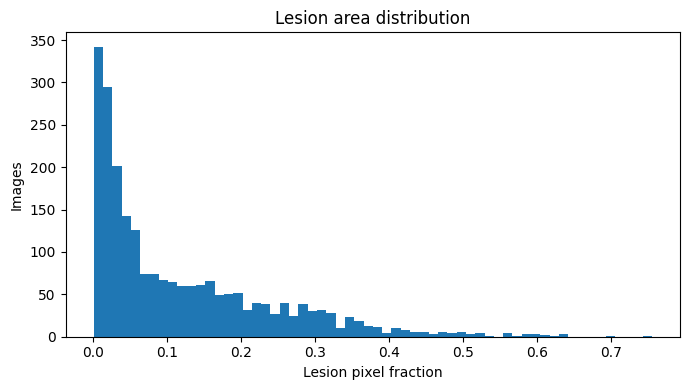

size_bin
<1%      254
1-5%     720
5-15%    587
>15%     710
Name: count, dtype: int64


In [8]:
# ============================================================
# 6a. CLASS-IMBALANCE DIAGNOSTIC
# ============================================================
frac = dataset_df["lesion_frac"].values
pos_rate = float(frac.mean())

print(f"Mean lesion pixel fraction : {pos_rate:.4f}  ({pos_rate*100:.2f}%)")
print(f"Median                     : {np.median(frac):.4f}")
print(f"Background : foreground    : {(1-pos_rate)/max(pos_rate,1e-9):.1f} : 1")
print(f"Images with <1% lesion     : {int((frac < 0.01).sum())}")
print(f"Images with <5% lesion     : {int((frac < 0.05).sum())}")

dataset_df["size_bin"] = pd.cut(dataset_df["lesion_frac"], bins=SIZE_BIN_EDGES,
                                 labels=SIZE_BIN_LABELS)

plt.figure(figsize=(7, 4))
plt.hist(frac, bins=60)
plt.xlabel("Lesion pixel fraction"); plt.ylabel("Images")
plt.title("Lesion area distribution")
plt.tight_layout()
plt.savefig(RUN_DIR / "lesion_area_distribution.png", dpi=140)
plt.show()

print(dataset_df["size_bin"].value_counts().sort_index())


In [9]:
# ============================================================
# 7. STRATIFIED SPLIT
# ============================================================
bins = pd.qcut(dataset_df["lesion_frac"].rank(method="first"),
               q=5, labels=False, duplicates="drop")

train_df, val_df = train_test_split(
    dataset_df, test_size=VAL_FRACTION, random_state=SEED,
    shuffle=True, stratify=bins,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

assert set(train_df["image_id"]).isdisjoint(set(val_df["image_id"])), "LEAK!"
assert len(train_df) >= BATCH_SIZE, "Train set smaller than one batch."

print("Total :", len(dataset_df), " Train :", len(train_df), " Val :", len(val_df))
print("Mean lesion frac  train:", round(train_df["lesion_frac"].mean(), 4),
      " val:", round(val_df["lesion_frac"].mean(), 4))
print("Split: PASS (stratified, no overlap)")
print()
print("Train size-bin counts:")
print(train_df["size_bin"].value_counts().sort_index())


Total : 2271  Train : 1816  Val : 455
Mean lesion frac  train: 0.1172  val: 0.1177
Split: PASS (stratified, no overlap)

Train size-bin counts:
size_bin
<1%      195
1-5%     584
5-15%    465
>15%     572
Name: count, dtype: int64


In [10]:
# ============================================================
# 8. LOADER + tf.data  (letterbox baseline + SCALE-CONSISTENT lesion window)
#
#    v2 bug being fixed here: the old crop resized the cropped region to FILL
#    IMG_SIZE (a zoom), so lesions looked much bigger in training than in
#    validation's full-frame letterbox. That mismatch is why small lesions
#    collapsed. This version resizes the crop by the SAME scale factor a
#    full-frame letterbox would use, then pastes it into the canvas at its
#    true position -- object pixel size stays identical to validation; only
#    the field of view (how much surrounding context is visible) changes.
# ============================================================
def letterbox(img, size, interp, pad_value=0):
    """Aspect-preserving resize into a size x size canvas."""
    h, w = img.shape[:2]
    scale = size / max(h, w)
    nh, nw = max(1, int(round(h * scale))), max(1, int(round(w * scale)))
    resized = cv2.resize(img, (nw, nh), interpolation=interp)

    top, left = (size - nh) // 2, (size - nw) // 2
    if resized.ndim == 3:
        canvas = np.full((size, size, resized.shape[2]), pad_value, dtype=resized.dtype)
        canvas[top:top + nh, left:left + nw, :] = resized
    else:
        canvas = np.full((size, size), pad_value, dtype=resized.dtype)
        canvas[top:top + nh, left:left + nw] = resized
    return canvas


def _lesion_crop_box(h, w, bx0, by0, bx1, by1, rng):
    """Pick a SQUARE crop box (pixel coords) around a lesion bbox with a
    random margin, clipped to stay inside the image."""
    bw, bh = (bx1 - bx0) * w, (by1 - by0) * h
    cx, cy = (bx0 + bx1) / 2.0 * w, (by0 + by1) / 2.0 * h

    margin = rng.uniform(CROP_MARGIN_LOW, CROP_MARGIN_HIGH)
    side = max(bw, bh) * margin
    side = min(side, min(h, w))   # never larger than the image itself

    jitter = side * 0.10
    cx += rng.uniform(-jitter, jitter)
    cy += rng.uniform(-jitter, jitter)

    x0 = int(round(np.clip(cx - side / 2, 0, w - side)))
    y0 = int(round(np.clip(cy - side / 2, 0, h - side)))
    return x0, y0, int(round(side)), int(round(side))


def _scale_consistent_crop_paste(image, mask, x0, y0, cw, ch, target_size):
    """Crop [y0:y0+ch, x0:x0+cw] out of the FULL-RESOLUTION image/mask, resize
    it by the SAME scale factor a full-frame letterbox of the ORIGINAL image
    would use, and paste it into a target_size x target_size zero canvas at
    the position it would actually occupy in that full letterboxed frame.
    This is the fix for the v2 scale mismatch -- see module docstring above."""
    h, w = image.shape[:2]
    s = target_size / max(h, w)                      # same scale as letterbox()
    full_nh, full_nw = int(round(h * s)), int(round(w * s))
    pad_top, pad_left = (target_size - full_nh) // 2, (target_size - full_nw) // 2

    new_cw, new_ch = max(1, int(round(cw * s))), max(1, int(round(ch * s)))
    crop_img = image[y0:y0 + ch, x0:x0 + cw]
    crop_mask = mask[y0:y0 + ch, x0:x0 + cw]
    resized_img = cv2.resize(crop_img, (new_cw, new_ch), interpolation=cv2.INTER_AREA)
    resized_mask = cv2.resize(crop_mask, (new_cw, new_ch), interpolation=cv2.INTER_NEAREST)

    place_x = int(round(pad_left + x0 * s))
    place_y = int(round(pad_top + y0 * s))

    canvas_img = np.zeros((target_size, target_size, 3), dtype=image.dtype)
    canvas_mask = np.zeros((target_size, target_size), dtype=mask.dtype)

    px0, py0 = max(0, place_x), max(0, place_y)
    ex, ey = min(target_size, place_x + new_cw), min(target_size, place_y + new_ch)
    sx0, sy0 = px0 - place_x, py0 - place_y

    if ex > px0 and ey > py0:
        canvas_img[py0:ey, px0:ex] = resized_img[sy0:sy0 + (ey - py0), sx0:sx0 + (ex - px0)]
        canvas_mask[py0:ey, px0:ex] = resized_mask[sy0:sy0 + (ey - py0), sx0:sx0 + (ex - px0)]

    return canvas_img, canvas_mask


def _load_np(image_path, mask_path, bbox, do_crop_flag):
    image_path = image_path.numpy().decode("utf-8")
    mask_path = mask_path.numpy().decode("utf-8")
    bbox = bbox.numpy()
    do_crop = bool(do_crop_flag.numpy())

    image = safe_imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Unreadable image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Unreadable mask: {mask_path}")

    h, w = image.shape[:2]
    has_bbox = bool(np.all(np.isfinite(bbox)))

    if do_crop and has_bbox:
        rng = np.random.default_rng()
        x0, y0, cw, ch = _lesion_crop_box(h, w, *bbox.tolist(), rng)
        image, mask = _scale_consistent_crop_paste(image, mask, x0, y0, cw, ch, IMG_SIZE)
    elif LETTERBOX_RESIZE:
        image = letterbox(image, IMG_SIZE, cv2.INTER_AREA, 0)
        mask = letterbox(mask, IMG_SIZE, cv2.INTER_NEAREST, 0)
    else:
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

    return (np.ascontiguousarray(image, dtype=np.float32),
            np.ascontiguousarray((mask > 127).astype(np.float32)[..., None]))


def tf_load(image_path, mask_path, bbox, training):
    do_crop = training and USE_CROP and (tf.random.uniform([]) < TRAIN_CROP_PROB)
    image, mask = tf.py_function(
        _load_np, [image_path, mask_path, bbox, do_crop],
        [tf.float32, tf.float32])
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask


In [11]:
# ============================================================
# 8b. OVERSAMPLING BY LESION-SIZE BIN (NEW)
#     Small-lesion images are a minority of the training set (see the
#     bin counts printed in Section 7). Rather than let the natural
#     frequency decide how often the model sees them, each size bin
#     becomes its own tf.data.Dataset (looping, shuffled) and
#     sample_from_datasets mixes them at fixed target weights every
#     epoch -- so <1% and 1-5% lesions show up far more often than
#     their raw count would produce.
# ============================================================
def _bin_dataset(df_bin, training):
    paths = df_bin["image_path"].values
    masks = df_bin["mask_path"].values
    bbox = df_bin[["bbox_x0", "bbox_y0", "bbox_x1", "bbox_y1"]].values.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, masks, bbox))
    if training:
        ds = ds.shuffle(max(len(df_bin), 1), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.repeat()
    ds = ds.map(lambda p, m, b: tf_load(p, m, b, training),
                num_parallel_calls=tf.data.AUTOTUNE, deterministic=not training)
    return ds


def make_train_dataset_oversampled(df):
    present_bins = [b for b in SIZE_BIN_LABELS if (df["size_bin"] == b).sum() > 0]
    weights = np.array([SIZE_BIN_TARGET_FREQ[b] for b in present_bins], dtype=np.float64)
    weights = weights / weights.sum()

    bin_datasets = [_bin_dataset(df[df["size_bin"] == b].reset_index(drop=True), training=True)
                    for b in present_bins]

    print("Oversampling weights (renormalized over present bins):")
    for b, wgt in zip(present_bins, weights):
        n = int((df["size_bin"] == b).sum())
        print(f"  {b:<8} n={n:<5} natural_freq={n/len(df):.3f}  target_freq={wgt:.3f}")

    ds = tf.data.Dataset.sample_from_datasets(bin_datasets, weights=weights.tolist(), seed=SEED)
    return ds


def make_dataset(df, training):
    if training and USE_OVERSAMPLE:
        ds = make_train_dataset_oversampled(df)
    else:
        paths = df["image_path"].values
        masks = df["mask_path"].values
        bbox = df[["bbox_x0", "bbox_y0", "bbox_x1", "bbox_y1"]].values.astype(np.float32)
        ds = tf.data.Dataset.from_tensor_slices((paths, masks, bbox))
        if training:
            ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(lambda p, m, b: tf_load(p, m, b, training),
                    num_parallel_calls=tf.data.AUTOTUNE, deterministic=not training)

    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE, deterministic=False)

    if USE_DEEP_SUP:
        ds = ds.map(add_deep_sup_targets, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(BATCH_SIZE, drop_remainder=training)
    return ds.prefetch(tf.data.AUTOTUNE)


def main_target(y):
    """Extract the full-resolution mask regardless of deep-supervision mode."""
    return y["head_out"] if isinstance(y, dict) else y


In [12]:
# ============================================================
# 9. AUGMENTATION (orientation-safe, geometry-consistent)
#    flip + affine + color jitter: unchanged from the original notebook,
#    always on, not implicated in the v2 regression.
#    elastic deform / cutout: gated by USE_ELASTIC / USE_CUTOUT (Section 2).
#
#    v2 bug being fixed here: cutout picked a random location with NO
#    awareness of the mask. For a <1% lesion, the cutout patch (8-20% of
#    image side) is the same size as the lesion's bounding box, so it
#    regularly erased the only lesion pixels in the image while the label
#    still said "lesion present" -- label noise concentrated on the hardest
#    class. Fixed version below samples a few candidate placements and
#    either uses the one that overlaps the lesion least, or skips cutout
#    for that sample entirely if even the best candidate overlaps too much.
# ============================================================
def _rand_affine(image, mask):
    """Rotation +/-15 deg, shift +/-8%, zoom 0.9-1.1 -- identical for both."""
    angle = tf.random.uniform([], -15.0, 15.0) * math.pi / 180.0
    zoom = tf.random.uniform([], 0.90, 1.10)
    dx = tf.random.uniform([], -0.08, 0.08) * IMG_SIZE
    dy = tf.random.uniform([], -0.08, 0.08) * IMG_SIZE

    cos_a, sin_a = tf.cos(angle) / zoom, tf.sin(angle) / zoom
    cx = cy = IMG_SIZE / 2.0

    a2 = cx - cx * cos_a + cy * sin_a + dx
    b2 = cy - cx * sin_a - cy * cos_a + dy
    transform = tf.stack([cos_a, -sin_a, a2, sin_a, cos_a, b2, 0.0, 0.0])[None, :]

    stacked = tf.concat([image, mask], axis=-1)[None, ...]
    warped = tf.raw_ops.ImageProjectiveTransformV3(
        images=stacked, transforms=transform,
        output_shape=tf.constant([IMG_SIZE, IMG_SIZE], tf.int32),
        interpolation="BILINEAR", fill_mode="CONSTANT", fill_value=0.0,
    )[0]

    return warped[..., :3], tf.cast(warped[..., 3:] > 0.5, tf.float32)


def _elastic_deform_np(image, mask, alpha, sigma):
    """Classic Simard-style elastic deformation via a smoothed random
    displacement field, applied identically to image and mask. Mask is
    squeezed to 2D before cv2.remap (cv2 is picky about a trailing size-1
    channel axis) and re-expanded after -- this was unhandled in v2."""
    shape = image.shape[:2]
    dx = cv2.GaussianBlur((np.random.rand(*shape).astype(np.float32) * 2 - 1),
                          (0, 0), sigma) * alpha
    dy = cv2.GaussianBlur((np.random.rand(*shape).astype(np.float32) * 2 - 1),
                          (0, 0), sigma) * alpha

    xs, ys = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    map_x = (xs + dx).astype(np.float32)
    map_y = (ys + dy).astype(np.float32)

    warped_img = cv2.remap(image, map_x, map_y, interpolation=cv2.INTER_LINEAR,
                           borderMode=cv2.BORDER_CONSTANT, borderValue=0)

    mask2d = mask[..., 0] if mask.ndim == 3 else mask
    warped_mask2d = cv2.remap(mask2d, map_x, map_y, interpolation=cv2.INTER_NEAREST,
                              borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    return warped_img.astype(np.float32), warped_mask2d[..., None].astype(np.float32)


def _elastic_deform_tf(image, mask):
    alpha = tf.random.uniform([], *ELASTIC_ALPHA_RANGE)
    sigma = tf.random.uniform([], *ELASTIC_SIGMA_RANGE)
    img_out, mask_out = tf.numpy_function(
        _elastic_deform_np, [image, mask, alpha, sigma], [tf.float32, tf.float32])
    img_out.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask_out.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return img_out, tf.cast(mask_out > 0.5, tf.float32)


def _cutout(image, mask):
    """Mask-aware cutout (fixed). Tries CUTOUT_NUM_CANDIDATES random square
    patches on the IMAGE only, measures each one's pixel overlap with the
    lesion mask, and applies whichever candidate overlaps least -- but only
    if that best candidate still stays under CUTOUT_MAX_LESION_OVERLAP.
    Otherwise this is a no-op for this sample: better to skip an augmentation
    than to silently erase the only positive label in a small-lesion image."""
    lesion_total = tf.reduce_sum(mask) + 1e-6

    holes, overlaps = [], []
    for _ in range(CUTOUT_NUM_CANDIDATES):
        frac = tf.random.uniform([], *CUTOUT_FRAC_RANGE)
        side = tf.cast(frac * IMG_SIZE, tf.int32)
        cy = tf.random.uniform([], 0, IMG_SIZE, dtype=tf.int32)
        cx = tf.random.uniform([], 0, IMG_SIZE, dtype=tf.int32)

        y0 = tf.clip_by_value(cy - side // 2, 0, IMG_SIZE)
        x0 = tf.clip_by_value(cx - side // 2, 0, IMG_SIZE)
        y1 = tf.clip_by_value(y0 + side, 0, IMG_SIZE)
        x1 = tf.clip_by_value(x0 + side, 0, IMG_SIZE)

        yy = tf.range(IMG_SIZE)[:, None]
        xx = tf.range(IMG_SIZE)[None, :]
        hole = tf.cast((yy >= y0) & (yy < y1) & (xx >= x0) & (xx < x1), tf.float32)[..., None]

        overlap = tf.reduce_sum(mask * hole) / lesion_total
        holes.append(hole)
        overlaps.append(overlap)

    overlaps_t = tf.stack(overlaps)
    holes_t = tf.stack(holes, axis=0)
    best_idx = tf.argmin(overlaps_t)
    best_hole = tf.gather(holes_t, best_idx)
    best_overlap = tf.gather(overlaps_t, best_idx)

    return tf.cond(best_overlap <= CUTOUT_MAX_LESION_OVERLAP,
                   lambda: image * (1.0 - best_hole),
                   lambda: image)


def augment(image, mask):
    if tf.random.uniform([]) > 0.5:                 # horizontal flip only
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)

    if tf.random.uniform([]) > 0.3:
        image, mask = _rand_affine(image, mask)

    if USE_ELASTIC and tf.random.uniform([]) < ELASTIC_PROB:
        image, mask = _elastic_deform_tf(image, mask)

    image = tf.image.random_brightness(image, 20.0)          # on [0,255]
    image = tf.image.random_contrast(image, 0.85, 1.15)
    image = tf.image.random_saturation(image, 0.85, 1.15)
    image = tf.image.random_hue(image, 0.02)
    image = tf.clip_by_value(image, 0.0, 255.0)

    if USE_CUTOUT and tf.random.uniform([]) < CUTOUT_PROB:
        image = _cutout(image, mask)

    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask


def add_deep_sup_targets(image, mask):
    """Targets keyed by output name so Keras matches them unambiguously."""
    m2 = tf.image.resize(mask, [IMG_SIZE // 2, IMG_SIZE // 2], method="nearest")
    m4 = tf.image.resize(mask, [IMG_SIZE // 4, IMG_SIZE // 4], method="nearest")
    return image, {"head_out": mask, "aux_out_2": m2, "aux_out_4": m4}


In [13]:
# ============================================================
# 9b. BUILD train_ds / val_ds
# ============================================================
train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)

_xb, _yb = next(iter(train_ds))
_main = main_target(_yb)

print("Image batch:", _xb.shape, "range",
      float(tf.reduce_min(_xb)), "-", float(tf.reduce_max(_xb)))
print("Mask batch :", _main.shape, "unique", np.unique(_main.numpy()))
assert np.all(np.isfinite(_xb.numpy()))
assert set(np.unique(_main.numpy())).issubset({0.0, 1.0})
print("Pipeline: PASS")


I0000 00:00:1790172222.425323      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


Oversampling weights (renormalized over present bins):
  <1%      n=195   natural_freq=0.107  target_freq=0.280
  1-5%     n=584   natural_freq=0.322  target_freq=0.270
  5-15%    n=465   natural_freq=0.256  target_freq=0.230
  >15%     n=572   natural_freq=0.315  target_freq=0.220
Image batch: (8, 256, 256, 3) range 0.0 - 255.0
Mask batch : (8, 256, 256, 1) unique [0. 1.]
Pipeline: PASS


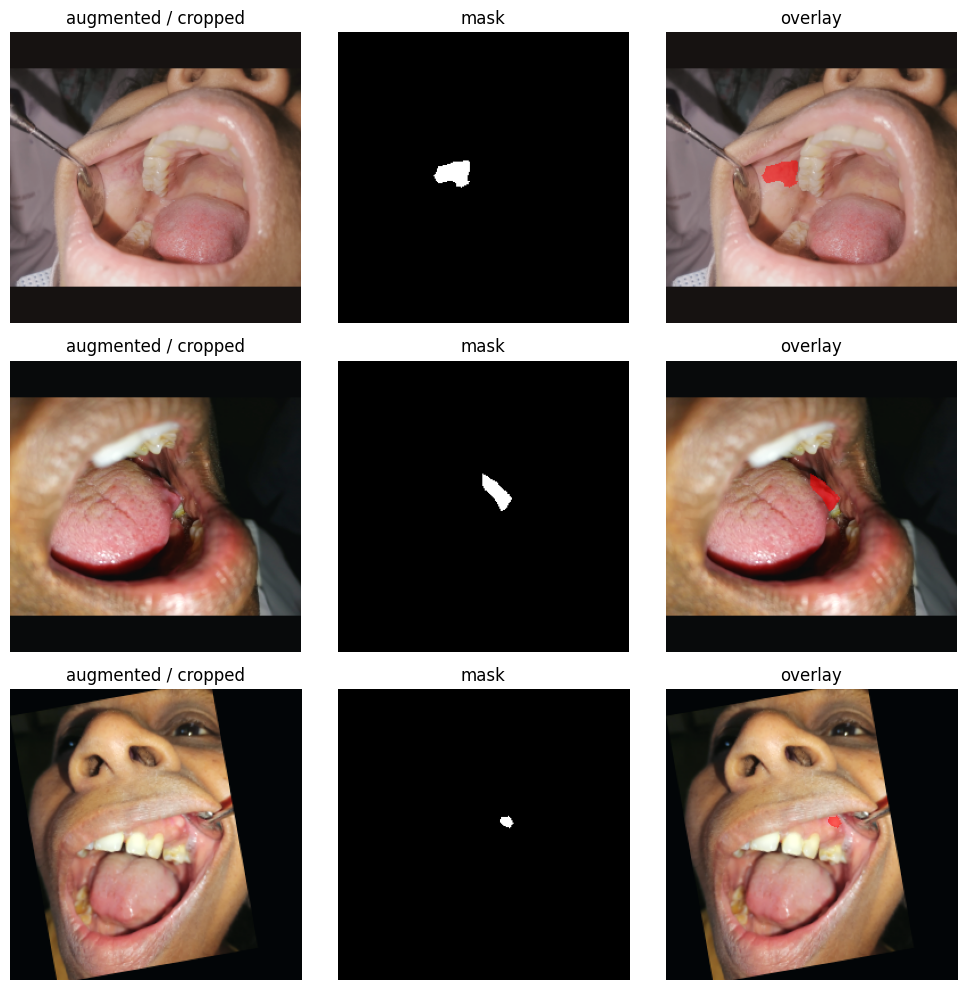

Lesion-fraction of these 3 mask crops: [0.008, 0.0057, 0.0013] -- should generally read higher than the raw lesion_frac column
since TRAIN_CROP_PROB = 0.35 of batches are lesion-centered crops.


In [14]:
# ============================================================
# 9c. VISUAL CHECK OF AUGMENTED / CROPPED BATCH
# ============================================================
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i in range(3):
    img = _xb[i].numpy().astype(np.uint8)
    msk = _main[i].numpy()[..., 0]
    ov = img.copy()
    sel = msk > 0.5
    ov[sel] = (0.45 * ov[sel] + 0.55 * np.array([255, 0, 0])).astype(np.uint8)

    axes[i, 0].imshow(img);              axes[i, 0].set_title("augmented / cropped")
    axes[i, 1].imshow(msk, cmap="gray"); axes[i, 1].set_title("mask")
    axes[i, 2].imshow(ov);               axes[i, 2].set_title("overlay")
    for c in range(3):
        axes[i, c].axis("off")

plt.tight_layout()
plt.savefig(RUN_DIR / "augmentation_check.png", dpi=140)
plt.show()
print("Lesion-fraction of these 3 mask crops:",
      [round(float((_main[i].numpy() > 0.5).mean()), 4) for i in range(3)],
      "-- should generally read higher than the raw lesion_frac column")
print("since TRAIN_CROP_PROB =", TRAIN_CROP_PROB, "of batches are lesion-centered crops.")


In [15]:
# ============================================================
# 10. LOSSES + METRICS (registered so model.save() works)
# ============================================================
SMOOTH = 1e-6


def _flat(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    n = tf.shape(y_true)[0]
    return tf.reshape(y_true, [n, -1]), tf.reshape(y_pred, [n, -1])


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def dice_coef(y_true, y_pred):
    yt, yp = _flat(y_true, y_pred)
    inter = tf.reduce_sum(yt * yp, axis=1)
    denom = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1)
    return tf.reduce_mean((2.0 * inter + SMOOTH) / (denom + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def iou_coef(y_true, y_pred):
    yt, yp = _flat(y_true, y_pred)
    inter = tf.reduce_sum(yt * yp, axis=1)
    union = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1) - inter
    return tf.reduce_mean((inter + SMOOTH) / (union + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def bin_dice(y_true, y_pred):
    """Hard Dice at 0.5 -- the reported number."""
    yt, yp = _flat(y_true, tf.cast(y_pred > 0.5, tf.float32))
    inter = tf.reduce_sum(yt * yp, axis=1)
    denom = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1)
    return tf.reduce_mean((2.0 * inter + SMOOTH) / (denom + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def bin_iou(y_true, y_pred):
    yt, yp = _flat(y_true, tf.cast(y_pred > 0.5, tf.float32))
    inter = tf.reduce_sum(yt * yp, axis=1)
    union = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1) - inter
    return tf.reduce_mean((inter + SMOOTH) / (union + SMOOTH))


def tversky_index(y_true, y_pred, alpha=TVERSKY_ALPHA, beta=TVERSKY_BETA):
    yt, yp = _flat(y_true, y_pred)
    tp = tf.reduce_sum(yt * yp, axis=1)
    fp = tf.reduce_sum((1.0 - yt) * yp, axis=1)
    fn = tf.reduce_sum(yt * (1.0 - yp), axis=1)
    return tf.reduce_mean((tp + SMOOTH) / (tp + alpha * fp + beta * fn + SMOOTH))


def focal_tversky_loss(y_true, y_pred, gamma=TVERSKY_GAMMA):
    return tf.pow(1.0 - tversky_index(y_true, y_pred), gamma)


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def combined_loss(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return BCE_WEIGHT * bce + TVERSKY_WEIGHT * focal_tversky_loss(y_true, y_pred)


METRICS = [dice_coef, iou_coef, bin_dice, bin_iou]

# quick numerical sanity check
_t = tf.constant(np.random.randint(0, 2, (2, 8, 8, 1)).astype(np.float32))
_p = tf.constant(np.random.rand(2, 8, 8, 1).astype(np.float32))
for fn in (dice_coef, iou_coef, bin_dice, bin_iou, combined_loss):
    v = float(fn(_t, _p))
    assert np.isfinite(v), f"{fn.__name__} not finite"
assert abs(float(dice_coef(_t, _t)) - 1.0) < 1e-4, "dice_coef(y,y) != 1"
assert float(combined_loss(_t, _t)) < 0.05, "loss on perfect prediction too high"
del _t, _p

print("Losses and metrics defined and sanity-checked.")
print("Loss = 0.5*BCE + 0.5*FocalTversky(alpha=0.3, beta=0.7, gamma=0.75)")


Losses and metrics defined and sanity-checked.
Loss = 0.5*BCE + 0.5*FocalTversky(alpha=0.3, beta=0.7, gamma=0.75)


In [16]:
# ============================================================
# 11. LAYER-NAME REGISTRY
#    Guarantees the duplicate-name crash can never happen again.
# ============================================================
class NameRegistry:
    """Hands out guaranteed-unique layer names and records every one."""

    def __init__(self):
        self.used = set()

    def reset(self):
        self.used = set()

    def __call__(self, name):
        if name in self.used:
            raise ValueError(
                f"Duplicate layer name generated: '{name}'. "
                "This is a builder bug -- fix the name prefix."
            )
        self.used.add(name)
        return name


NAMES = NameRegistry()
print("Name registry ready. Every layer name is asserted unique at build time.")


Name registry ready. Every layer name is asserted unique at build time.


In [17]:
# ============================================================
# 12. MOBILE-UNET BLOCKS (100% depthwise separable)
# ============================================================
@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
class CBAM(layers.Layer):
    """Channel + spatial attention. No Lambda -> clean .keras serialization."""

    def __init__(self, reduction_ratio=8, spatial_kernel=7, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = int(reduction_ratio)
        self.spatial_kernel = int(spatial_kernel)

    def build(self, input_shape):
        c = int(input_shape[-1])
        r = max(c // self.reduction_ratio, 4)
        self.mlp1 = layers.Dense(r, activation="relu", name="ch_reduce")
        self.mlp2 = layers.Dense(c, activation=None, name="ch_expand")
        self.sp_conv = layers.Conv2D(1, self.spatial_kernel, padding="same",
                                     activation="sigmoid", name="sp_conv")
        super().build(input_shape)

    def call(self, x):
        avg = tf.reduce_mean(x, axis=[1, 2])
        mx = tf.reduce_max(x, axis=[1, 2])
        att = tf.nn.sigmoid(self.mlp2(self.mlp1(avg)) + self.mlp2(self.mlp1(mx)))
        x = x * att[:, None, None, :]

        sp = tf.concat([tf.reduce_mean(x, -1, keepdims=True),
                        tf.reduce_max(x, -1, keepdims=True)], axis=-1)
        return x * self.sp_conv(sp)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"reduction_ratio": self.reduction_ratio,
                    "spatial_kernel": self.spatial_kernel})
        return cfg


def sep_block(x, filters, prefix, act, dilation=1):
    """Separable conv -> BN -> activation."""
    x = layers.SeparableConv2D(
        filters, 3, padding="same", use_bias=False, dilation_rate=dilation,
        name=NAMES(f"{prefix}_sep"))(x)
    x = layers.BatchNormalization(name=NAMES(f"{prefix}_bn"))(x)
    return layers.Activation(act, name=NAMES(f"{prefix}_act"))(x)


def residual_sep_block(x, filters, prefix, act, dropout=0.0):
    """Two separable convs + 1x1 projection shortcut."""
    shortcut = layers.Conv2D(filters, 1, padding="same", use_bias=False,
                             name=NAMES(f"{prefix}_sc"))(x)
    shortcut = layers.BatchNormalization(name=NAMES(f"{prefix}_sc_bn"))(shortcut)

    y = sep_block(x, filters, f"{prefix}_a", act)
    if dropout > 0:
        y = layers.SpatialDropout2D(dropout, name=NAMES(f"{prefix}_inner_drop"))(y)
    y = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False,
                               name=NAMES(f"{prefix}_b_sep"))(y)
    y = layers.BatchNormalization(name=NAMES(f"{prefix}_b_bn"))(y)

    out = layers.Add(name=NAMES(f"{prefix}_add"))([shortcut, y])
    return layers.Activation(act, name=NAMES(f"{prefix}_out"))(out)


def double_block(x, filters, prefix, residual, act, dropout):
    """Either two plain separable convs (v1 style) or one residual block."""
    if residual:
        return residual_sep_block(x, filters, prefix, act, dropout)
    x = sep_block(x, filters, f"{prefix}_a", act)
    x = sep_block(x, filters, f"{prefix}_b", act)
    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=NAMES(f"{prefix}_inner_drop"))(x)
    return x


def attention_gate(skip, gating, filters, prefix):
    """Additive attention gate applied to a skip connection."""
    g = layers.Conv2D(filters, 1, padding="same", name=NAMES(f"{prefix}_g"))(gating)
    s = layers.Conv2D(filters, 1, padding="same", name=NAMES(f"{prefix}_x"))(skip)
    a = layers.Add(name=NAMES(f"{prefix}_add"))([g, s])
    a = layers.Activation("relu", name=NAMES(f"{prefix}_relu"))(a)
    psi = layers.Conv2D(1, 1, padding="same", activation="sigmoid",
                        name=NAMES(f"{prefix}_psi"))(a)
    return layers.Multiply(name=NAMES(f"{prefix}_mul"))([skip, psi])


def sep_aspp(x, filters, prefix, act, rates=(1, 2, 4, 8)):
    """Separable atrous spatial pyramid. Branch width is capped so the
    48-filter variant does not explode to millions of parameters."""
    branch_f = int(min(filters, ASPP_MAX_FILTERS))

    branches = [layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                              name=NAMES(f"{prefix}_b0_conv"))(x)]
    for i, r in enumerate(rates[1:], start=1):
        branches.append(sep_block(x, branch_f, f"{prefix}_b{i}", act, dilation=r))

    pooled = layers.GlobalAveragePooling2D(
        keepdims=True, name=NAMES(f"{prefix}_gap"))(x)
    pooled = layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                           name=NAMES(f"{prefix}_gap_conv"))(pooled)
    pooled = layers.UpSampling2D(size=(int(x.shape[1]), int(x.shape[2])),
                                 interpolation="bilinear",
                                 name=NAMES(f"{prefix}_gap_up"))(pooled)
    branches.append(pooled)

    merged = layers.Concatenate(name=NAMES(f"{prefix}_cat"))(branches)
    merged = layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                           name=NAMES(f"{prefix}_proj"))(merged)
    merged = layers.BatchNormalization(name=NAMES(f"{prefix}_proj_bn"))(merged)
    return layers.Activation(act, name=NAMES(f"{prefix}_proj_act"))(merged)


print("Mobile-UNet blocks defined (no external backbone, no pretrained weights).")


Mobile-UNet blocks defined (no external backbone, no pretrained weights).


In [18]:
# ============================================================
# 13. EFFICIENTNETB0 + CUSTOM DECODER BUILDER
#
#     Skip connections: the four standard EfficientNet-UNet stage-boundary
#     layers. For a 256px input these sit at:
#       block2a_expand_activation  -> 128x128x96
#       block3a_expand_activation  ->  64x64x144
#       block4a_expand_activation  ->  32x32x240
#       block6a_expand_activation  ->  16x16x672
#       top_activation (bottleneck)->   8x8x1280
#     EfficientNet's stem downsamples immediately, so there is no encoder
#     feature at the input's native resolution -- a small "stem skip" (a
#     couple of separable convs run directly on the raw input) supplies that
#     detail at the final decoder stage instead.
# ============================================================
EFFNET_SKIP_LAYER_NAMES = [
    "block2a_expand_activation",
    "block3a_expand_activation",
    "block4a_expand_activation",
    "block6a_expand_activation",
]
EFFNET_BOTTLENECK_LAYER_NAME = "top_activation"


def build_efficientnet_unet(img_size, gates, cbam, aspp, deep_sup, dropout, act,
                            name="effnet_unet"):
    NAMES.reset()

    inputs = layers.Input(shape=(img_size, img_size, 3), name=NAMES("input_image"))

    base = tf.keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet", input_tensor=inputs)
    base._name = "efficientnetb0_encoder"

    stem_skip = sep_block(
        layers.Rescaling(1.0 / 255.0, name=NAMES("stem_rescale"))(inputs),
        24, "stem_skip", act)

    skip_tensors = [base.get_layer(n).output for n in EFFNET_SKIP_LAYER_NAMES]
    x = base.get_layer(EFFNET_BOTTLENECK_LAYER_NAME).output

    if aspp:
        bneck_filters = int(x.shape[-1])
        x = sep_aspp(x, min(bneck_filters, ASPP_MAX_FILTERS), "bneck_aspp", act)
    if cbam:
        x = CBAM(CBAM_REDUCTION, name=NAMES("bottleneck_cbam"))(x)
    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=NAMES("bottleneck_drop"))(x)

    aux_outputs = {}
    dec_filters = 256

    for skip in reversed(skip_tensors):     # lowest-res skip (16) first, up to highest (128)
        res = int(skip.shape[1])
        x = layers.UpSampling2D(2, interpolation="bilinear",
                                name=NAMES(f"dec_up_to{res}"))(x)
        if gates:
            skip_use = attention_gate(skip, x, max(dec_filters // 2, 8), f"dec_gate{res}")
        else:
            skip_use = skip
        x = layers.Concatenate(name=NAMES(f"dec_cat{res}"))([x, skip_use])
        x = residual_sep_block(x, dec_filters, f"dec_blk{res}", act,
                               dropout if res <= 64 else 0.0)

        out_res = int(x.shape[1])
        if deep_sup and out_res in (img_size // 2, img_size // 4):
            aux_name = f"aux_out_{img_size // out_res}"
            aux_outputs[aux_name] = layers.Conv2D(
                1, 1, activation="sigmoid", dtype="float32",
                name=NAMES(aux_name))(x)

        dec_filters = max(dec_filters // 2, 32)

    # final upsample to full input resolution, fused with the stem skip
    x = layers.UpSampling2D(2, interpolation="bilinear", name=NAMES("dec_final_up"))(x)
    x = layers.Concatenate(name=NAMES("dec_final_cat"))([x, stem_skip])
    x = residual_sep_block(x, 32, "dec_final", act, 0.0)

    main_out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32",
                             name=NAMES("head_out"))(x)

    if deep_sup:
        outputs = [main_out, aux_outputs["aux_out_2"], aux_outputs["aux_out_4"]]
        model = models.Model(inputs, outputs, name=name)
    else:
        model = models.Model(inputs, main_out, name=name)

    all_names = [l.name for l in model.layers]
    dupes = [n for n, c in Counter(all_names).items() if c > 1]
    assert not dupes, f"Duplicate layer names: {dupes}"

    return model, base


print("EfficientNetB0 + decoder builder defined.")
print("Skip layers  :", EFFNET_SKIP_LAYER_NAMES)
print("Bottleneck   :", EFFNET_BOTTLENECK_LAYER_NAME)


EfficientNetB0 + decoder builder defined.
Skip layers  : ['block2a_expand_activation', 'block3a_expand_activation', 'block4a_expand_activation', 'block6a_expand_activation']
Bottleneck   : top_activation


In [19]:
# ============================================================
# 15. BUILD THE MODEL -- EfficientNetB0 encoder + custom decoder
# ============================================================
tf.keras.backend.clear_session()
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

model, encoder_base = build_efficientnet_unet(
    img_size=IMG_SIZE,
    gates=USE_GATES,
    cbam=USE_CBAM,
    aspp=USE_ASPP,
    deep_sup=USE_DEEP_SUP,
    dropout=DROPOUT,
    act=ACTIVATION,
    name=f"lesion_{RUN_LABEL}",
)

total_params = int(model.count_params())
encoder_params = int(encoder_base.count_params())
decoder_params = total_params - encoder_params
fp32_mb = total_params * 4 / (1024 ** 2)

V1_PARAMS, V1_DICE, V1_IOU = 311319, 0.30052751, 0.19818199
CUSTOM_ARCH_PARAMS, CUSTOM_ARCH_DICE = 1_191_117, 0.5515   # your v4 deep_sup run, for scale

print("=" * 66)
print("MODEL SIZE")
print("=" * 66)
print(f"{'Model':<28}{model.name}")
print(f"{'Total params':<28}{total_params:>14,}")
print(f"{'  encoder (EfficientNetB0)':<28}{encoder_params:>14,}  ({100*encoder_params/total_params:.0f}%)")
print(f"{'  decoder (custom)':<28}{decoder_params:>14,}  ({100*decoder_params/total_params:.0f}%)")
print(f"{'FP32 weights (MB)':<28}{fp32_mb:>14.2f}")
print(f"{'FP16 activations (~)':<28}{'mixed_float16 active -- ~2x less activation RAM':>14}")
print("-" * 66)
print(f"{'v1 custom (from scratch)':<28}{V1_PARAMS:>14,}  Dice {V1_DICE:.4f}")
print(f"{'v4 custom deep_sup run':<28}{CUSTOM_ARCH_PARAMS:>14,}  Dice {CUSTOM_ARCH_DICE:.4f}")
print(f"{'this model':<28}{total_params:>14,}  Dice (pending)")
print(f"{'Capacity vs v1':<28}{total_params / V1_PARAMS:>13.2f}x")
print(f"{'Capacity vs v4 custom':<28}{total_params / CUSTOM_ARCH_PARAMS:>13.2f}x")
print("=" * 66)
print("Total layers          :", len(model.layers))
print("Output(s)             :", [tuple(o.shape) for o in model.outputs]
      if isinstance(model.output, list) else model.output_shape)
print("Architecture family   : EfficientNetB0 (ImageNet pretrained) + custom decoder")
print("Transfer learning     : YES -- encoder pretrained, see intro markdown")


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MODEL SIZE
Model                       lesion_v5_effnetb0
Total params                     6,397,936
  encoder (EfficientNetB0)       4,049,571  (63%)
  decoder (custom)               2,348,365  (37%)
FP32 weights (MB)                    24.41
FP16 activations (~)        mixed_float16 active -- ~2x less activation RAM
------------------------------------------------------------------
v1 custom (from scratch)           311,319  Dice 0.3005
v4 custom deep_sup run           1,191,117  Dice 0.5515
this model                       6,397,936  Dice (pending)
Capacity vs v1                      20.55x
Capacity vs v4 custom                5.37x
Total layers          : 346
Output(s)             : [(None, 256, 256, 1), (None, 128, 128, 1), (None, 64, 64, 1)]
Architecture family   : EfficientNetB0 (ImageNet pretrained) + custom decoder
Transfer learning     : YES -- encoder pretrained, see intro markdown


In [20]:
# ============================================================
# 16. HARD PREFLIGHT -- NOTHING TRAINS BEFORE THIS PASSES
# ============================================================
checks = []

vx, vy = next(iter(val_ds))
vy_main = main_target(vy)

out = model(vx, training=False)
pred = out[0] if isinstance(out, (list, tuple)) else out

checks.append(("output shape matches target", tuple(pred.shape) == tuple(vy_main.shape)))
checks.append(("prediction finite", bool(np.all(np.isfinite(pred.numpy())))))
checks.append(("prediction in [0,1]",
               float(pred.numpy().min()) >= 0.0 and float(pred.numpy().max()) <= 1.0))
checks.append(("masks binary", set(np.unique(vy_main.numpy())).issubset({0.0, 1.0})))
checks.append(("images in [0,255]",
               float(vx.numpy().min()) >= 0.0 and float(vx.numpy().max()) <= 255.0))

loss_val = float(combined_loss(vy_main, pred))
checks.append(("loss finite", bool(np.isfinite(loss_val))))
checks.append(("train batches > 0", len(train_df) // BATCH_SIZE > 0))
checks.append(("no train/val leak",
               set(train_df["image_id"]).isdisjoint(set(val_df["image_id"]))))
checks.append(("unique layer names",
               len({l.name for l in model.layers}) == len(model.layers)))

if USE_DEEP_SUP:
    checks.append(("3 outputs for deep supervision", len(model.outputs) == 3))
    checks.append(("aux target keys match outputs",
                   set(vy.keys()) == {"head_out", "aux_out_2", "aux_out_4"}))

with tf.GradientTape() as tape:
    o = model(vx, training=True)
    p = o[0] if isinstance(o, (list, tuple)) else o
    l = combined_loss(vy_main, p)
grads = tape.gradient(l, model.trainable_weights)
nonzero = sum(1 for g in grads if g is not None and float(tf.reduce_max(tf.abs(g))) > 0)
checks.append((f"gradients flow ({nonzero}/{len(grads)})", nonzero > 0.8 * len(grads)))

print(f"{'check':<44}{'result':>8}")
print("-" * 52)
for label, ok in checks:
    print(f"{label:<44}{'PASS' if ok else 'FAIL':>8}")
print("-" * 52)
assert all(ok for _, ok in checks), "STOP: preflight failed -- fix before training."
print("Preflight: ALL PASS")


check                                         result
----------------------------------------------------
output shape matches target                     PASS
prediction finite                               PASS
prediction in [0,1]                             PASS
masks binary                                    PASS
images in [0,255]                               PASS
loss finite                                     PASS
train batches > 0                               PASS
no train/val leak                               PASS
unique layer names                              PASS
3 outputs for deep supervision                  PASS
aux target keys match outputs                   PASS
gradients flow (319/323)                        PASS
----------------------------------------------------
Preflight: ALL PASS


In [21]:
# ============================================================
# 17. LR SCHEDULE + A COMPILE HELPER FOR BOTH TRAINING PHASES
#     Two-phase training (Section 18) needs to recompile the model when
#     encoder.trainable flips, so the actual optimizer/compile call is a
#     function here rather than a one-shot cell.
# ============================================================
steps_per_epoch = max(1, len(train_df) // BATCH_SIZE // GRAD_ACCUM_STEPS)


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
class WarmupCosine(tf.keras.optimizers.schedules.LearningRateSchedule):
    """Linear warmup then cosine decay. Registered so model.save() works."""

    def __init__(self, base_lr, total_steps, warmup_steps, min_lr_ratio=0.02):
        super().__init__()
        self.base_lr = float(base_lr)
        self.total_steps = int(total_steps)
        self.warmup_steps = int(warmup_steps)
        self.min_lr_ratio = float(min_lr_ratio)

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = tf.cast(tf.maximum(self.warmup_steps, 1), tf.float32)
        total = tf.cast(tf.maximum(self.total_steps, 1), tf.float32)

        warm_lr = self.base_lr * (step / warm)
        prog = tf.clip_by_value((step - warm) / tf.maximum(total - warm, 1.0), 0.0, 1.0)
        cos_lr = self.base_lr * (
            self.min_lr_ratio
            + (1.0 - self.min_lr_ratio) * 0.5 * (1.0 + tf.cos(math.pi * prog))
        )
        return tf.where(step < warm, warm_lr, cos_lr)

    def get_config(self):
        return {"base_lr": self.base_lr, "total_steps": self.total_steps,
                "warmup_steps": self.warmup_steps, "min_lr_ratio": self.min_lr_ratio}


def compile_for_phase(base_lr, total_epochs, warmup_epochs):
    """(Re)compiles the global `model` with a fresh optimizer/schedule sized
    for this phase's own epoch budget, and returns (schedule, MONITOR key)."""
    schedule = WarmupCosine(
        base_lr,
        total_steps=total_epochs * steps_per_epoch,
        warmup_steps=warmup_epochs * steps_per_epoch,
    )
    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=schedule, weight_decay=WEIGHT_DECAY,
        global_clipnorm=GLOBAL_CLIPNORM,
    )
    if mixed_precision.global_policy().name == "mixed_float16":
        optimizer = mixed_precision.LossScaleOptimizer(optimizer)

    if USE_DEEP_SUP:
        model.compile(
            optimizer=optimizer,
            loss={k: combined_loss for k in DEEP_SUP_WEIGHTS},
            loss_weights=dict(DEEP_SUP_WEIGHTS),
            metrics={"head_out": METRICS},
            steps_per_execution=1,
        )
        monitor = "val_head_out_bin_dice"
    else:
        model.compile(optimizer=optimizer, loss=combined_loss, metrics=METRICS,
                      steps_per_execution=1)
        monitor = "val_bin_dice"
    return schedule, monitor


if USE_DEEP_SUP:
    MONITOR = "val_head_out_bin_dice"
    DICE_COL, IOU_COL = "head_out_bin_dice", "head_out_bin_iou"
else:
    MONITOR = "val_bin_dice"
    DICE_COL, IOU_COL = "bin_dice", "bin_iou"

print("Steps/epoch (weight updates):", steps_per_epoch)
print("Monitor     :", MONITOR)
print("Phase 1 LR  :", PHASE1_LR, " over", PHASE1_EPOCHS, "epochs (encoder frozen)")
print("Phase 2 LR  :", PHASE2_LR, " over", PHASE2_EPOCHS, "epochs (encoder fine-tuned)")


Steps/epoch (weight updates): 227
Monitor     : val_head_out_bin_dice
Phase 1 LR  : 0.0003  over 15 epochs (encoder frozen)
Phase 2 LR  : 1e-05  over 35 epochs (encoder fine-tuned)


In [22]:
# ============================================================
# 18. TRAIN -- TWO PHASES: encoder frozen, then encoder fine-tuned
# ============================================================
BEST_WEIGHTS   = RUN_DIR / f"{RUN_LABEL}_best.weights.h5"
PHASE1_WEIGHTS = RUN_DIR / f"{RUN_LABEL}_phase1_best.weights.h5"
PHASE2_WEIGHTS = RUN_DIR / f"{RUN_LABEL}_phase2_best.weights.h5"
FINAL_MODEL    = RUN_DIR / f"{RUN_LABEL}_final.keras"
FINAL_WEIGHTS  = RUN_DIR / f"{RUN_LABEL}_final.weights.h5"
HISTORY_CSV    = RUN_DIR / f"{RUN_LABEL}_history.csv"
PHASE1_CSV     = RUN_DIR / f"{RUN_LABEL}_phase1_history.csv"
PHASE2_CSV     = RUN_DIR / f"{RUN_LABEL}_phase2_history.csv"
SWA_POOL_DIR   = RUN_DIR / f"{RUN_LABEL}_swa_pool"
if USE_SWA:
    SWA_POOL_DIR.mkdir(parents=True, exist_ok=True)


class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self._t0)


class SwaCheckpointPool(tf.keras.callbacks.Callback):
    """Rolling window of the last SWA_LAST_N_EPOCHS checkpoints on disk."""

    def __init__(self, pool_dir, keep_last_n):
        super().__init__()
        self.pool_dir = Path(pool_dir)
        self.keep_last_n = keep_last_n
        self.saved = []

    def on_epoch_end(self, epoch, logs=None):
        path = self.pool_dir / f"epoch_{epoch:03d}.weights.h5"
        self.model.save_weights(str(path))
        self.saved.append(path)
        while len(self.saved) > self.keep_last_n:
            old = self.saved.pop(0)
            old.unlink(missing_ok=True)


t_start_total = time.time()

# ---------------- PHASE 1: encoder frozen, decoder-only warm-up ----------------
encoder_base.trainable = False
schedule1, _ = compile_for_phase(PHASE1_LR, PHASE1_EPOCHS, PHASE1_WARMUP_EPOCHS)
trainable_phase1 = int(sum(np.prod(v.shape) for v in model.trainable_weights))

print("=" * 70)
print("PHASE 1 -- ENCODER FROZEN")
print("=" * 70)
print("Trainable params this phase:", f"{trainable_phase1:,}", "of", f"{total_params:,}", "total")
print("Epochs:", PHASE1_EPOCHS, " LR:", PHASE1_LR)
print("=" * 70)

timer1 = EpochTimer()
callbacks1 = [
    tf.keras.callbacks.ModelCheckpoint(
        str(PHASE1_WEIGHTS), monitor=MONITOR, mode="max",
        save_best_only=True, save_weights_only=True, verbose=1),
    tf.keras.callbacks.CSVLogger(str(PHASE1_CSV), append=False),
    tf.keras.callbacks.TerminateOnNaN(),
    timer1,
]

t1 = time.time()
try:
    history1 = model.fit(
        train_ds, validation_data=val_ds, epochs=PHASE1_EPOCHS,
        steps_per_epoch=steps_per_epoch, callbacks=callbacks1, verbose=1,
    )
except tf.errors.ResourceExhaustedError:
    print("=" * 70); print("OUT OF GPU MEMORY IN PHASE 1")
    print(f"Halve BATCH_SIZE ({BATCH_SIZE} -> {max(1, BATCH_SIZE // 2)}) in Section 2, "
          "restart, rerun.")
    print("=" * 70)
    raise
phase1_seconds = time.time() - t1
phase1_epochs_run = len(history1.history["loss"])

# ---------------- PHASE 2: unfreeze, fine-tune at low LR ----------------
encoder_base.trainable = True
_bn_frozen = 0
for layer in encoder_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
        _bn_frozen += 1
schedule2, _ = compile_for_phase(PHASE2_LR, PHASE2_EPOCHS, PHASE2_WARMUP_EPOCHS)
trainable_phase2 = int(sum(np.prod(v.shape) for v in model.trainable_weights))

print()
print("=" * 70)
print("PHASE 2 -- ENCODER UNFROZEN (fine-tune), BatchNorm layers kept frozen")
print("=" * 70)
print("BatchNorm layers kept frozen inside encoder:", _bn_frozen)
print("Trainable params this phase:", f"{trainable_phase2:,}", "of", f"{total_params:,}", "total")
print("Epochs:", PHASE2_EPOCHS, " LR:", PHASE2_LR)
print("=" * 70)

timer2 = EpochTimer()
swa_pool = None
callbacks2 = [
    tf.keras.callbacks.ModelCheckpoint(
        str(PHASE2_WEIGHTS), monitor=MONITOR, mode="max",
        save_best_only=True, save_weights_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR, mode="max", patience=EARLY_STOP_PATIENCE,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.CSVLogger(str(PHASE2_CSV), append=False),
    tf.keras.callbacks.TerminateOnNaN(),
    timer2,
]
if USE_SWA:
    swa_pool = SwaCheckpointPool(SWA_POOL_DIR, SWA_LAST_N_EPOCHS)
    callbacks2.append(swa_pool)

t2 = time.time()
try:
    history2 = model.fit(
        train_ds, validation_data=val_ds, epochs=PHASE2_EPOCHS,
        steps_per_epoch=steps_per_epoch, callbacks=callbacks2, verbose=1,
    )
except tf.errors.ResourceExhaustedError:
    print("=" * 70); print("OUT OF GPU MEMORY IN PHASE 2")
    print(f"Halve BATCH_SIZE ({BATCH_SIZE} -> {max(1, BATCH_SIZE // 2)}) in Section 2, "
          "restart, rerun. Phase 2 (whole network unfrozen) uses noticeably more "
          "memory than phase 1.")
    print("=" * 70)
    raise
phase2_seconds = time.time() - t2
phase2_epochs_run = len(history2.history["loss"])

training_seconds = time.time() - t_start_total

# ---------------- Combine histories into one CSV for Section 20 ----------------
h1_df = pd.read_csv(PHASE1_CSV); h1_df["phase"] = 1
h2_df = pd.read_csv(PHASE2_CSV); h2_df["phase"] = 2
combined = pd.concat([h1_df, h2_df], ignore_index=True)
combined.to_csv(HISTORY_CSV, index=False)
PHASE_BOUNDARY_EPOCH = len(h1_df)   # for the vertical marker in Section 20's plot

# ---------------- Pick the winner: phase1-best vs phase2-best ----------------
model.load_weights(str(PHASE2_WEIGHTS))
phase2_eval = model.evaluate(val_ds, verbose=0, return_dict=True)
model.load_weights(str(PHASE1_WEIGHTS))
phase1_eval = model.evaluate(val_ds, verbose=0, return_dict=True)

_key = "head_out_bin_dice" if USE_DEEP_SUP else "bin_dice"
phase1_dice = phase1_eval.get(_key, phase1_eval.get(f"val_{_key}"))
phase2_dice = phase2_eval.get(_key, phase2_eval.get(f"val_{_key}"))

print()
print("=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)
print(f"Phase 1 (frozen)     : {phase1_epochs_run} epochs, {phase1_seconds/60:.1f} min, "
      f"val {_key} = {phase1_dice:.4f}")
print(f"Phase 2 (fine-tuned) : {phase2_epochs_run} epochs, {phase2_seconds/60:.1f} min, "
      f"val {_key} = {phase2_dice:.4f}")
print(f"Total training time  : {training_seconds/60:.1f} min")

if phase2_dice >= phase1_dice:
    print("Phase 2 (fine-tuned) wins -- using those weights.")
    model.load_weights(str(PHASE2_WEIGHTS))
    model.save_weights(str(BEST_WEIGHTS))
else:
    print("Phase 1 (frozen encoder) wins -- fine-tuning made things worse, using phase 1 weights.")
    model.load_weights(str(PHASE1_WEIGHTS))
    model.save_weights(str(BEST_WEIGHTS))

if USE_SWA and swa_pool is not None:
    print("SWA pool has:", len(swa_pool.saved), "checkpoint(s) on disk (phase 2 only):",
          [p.name for p in swa_pool.saved])


PHASE 1 -- ENCODER FROZEN
Trainable params this phase: 2,343,709 of 6,397,936 total
Epochs: 15  LR: 0.0003
Epoch 1/15


2026-09-23 14:04:47.835597: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 14:04:47.971923: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 14:04:48.291873: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 14:04:48.433940: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 14:04:49.232654: E external/local_xla/xla/stream_

154/227 ━━━━━━━━━━━━━━━━━━━━ 37s 520ms/step - aux_out_2_loss: 0.6989 - aux_out_4_loss: 0.7906 - head_out_bin_dice: 0.1996 - head_out_bin_iou: 0.1261 - head_out_dice_coef: 0.1368 - head_out_iou_coef: 0.0800 - head_out_loss: 0.7207 - loss: 1.1583

Premature end of JPEG file


227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 525ms/step - aux_out_2_loss: 0.6782 - aux_out_4_loss: 0.7563 - head_out_bin_dice: 0.2298 - head_out_bin_iou: 0.1505 - head_out_dice_coef: 0.1507 - head_out_iou_coef: 0.0897 - head_out_loss: 0.6941 - loss: 1.1166

2026-09-23 14:08:25.626801: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 14:08:25.762564: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 14:08:26.082084: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 14:08:26.223960: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-23 14:08:27.012851: E external/local_xla/xla/stream_

... (69 outputs left out)

Premature end of JPEG file


227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 429ms/step - aux_out_2_loss: 0.2386 - aux_out_4_loss: 0.2448 - head_out_bin_dice: 0.6928 - head_out_bin_iou: 0.5645 - head_out_dice_coef: 0.6681 - head_out_iou_coef: 0.5341 - head_out_loss: 0.2367 - loss: 0.3811

Premature end of JPEG file



Epoch 35: val_head_out_bin_dice did not improve from 0.59134
227/227 ━━━━━━━━━━━━━━━━━━━━ 155s 687ms/step - aux_out_2_loss: 0.2360 - aux_out_4_loss: 0.2416 - head_out_bin_dice: 0.7054 - head_out_bin_iou: 0.5787 - head_out_dice_coef: 0.6816 - head_out_iou_coef: 0.5487 - head_out_loss: 0.2342 - loss: 0.3769 - val_aux_out_2_loss: 0.3525 - val_aux_out_4_loss: 0.3548 - val_head_out_bin_dice: 0.5879 - val_head_out_bin_iou: 0.4722 - val_head_out_dice_coef: 0.5735 - val_head_out_iou_coef: 0.4534 - val_head_out_loss: 0.3538 - val_loss: 0.5660
Restoring model weights from the end of the best epoch: 18.

TRAINING COMPLETE
Phase 1 (frozen)     : 15 epochs, 40.6 min, val head_out_bin_dice = 0.5731
Phase 2 (fine-tuned) : 35 epochs, 95.2 min, val head_out_bin_dice = 0.5913
Total training time  : 135.8 min
Phase 2 (fine-tuned) wins -- using those weights.
SWA pool has: 6 checkpoint(s) on disk (phase 2 only): ['epoch_029.weights.h5', 'epoch_030.weights.h5', 'epoch_031.weights.h5', 'epoch_032.weights.h

In [23]:
# ============================================================
# 19b. SWA -- STOCHASTIC WEIGHT AVERAGING (phase 2 only)
#      Averages only phase 2's (fine-tuning) checkpoints -- averaging across
#      the frozen/unfrozen boundary would blend two different training
#      regimes together, which doesn't mean anything. Compares against
#      whichever of phase1/phase2 already won (Section 18), not just phase 2
#      alone, so SWA has to beat the actual best checkpoint to be used.
# ============================================================
swa_model = None
swa_dice = None
best_dice_single = max(phase1_dice, phase2_dice)

if not USE_SWA:
    print("USE_SWA=False -- skipping, the phase1/phase2 winner's weights stand as-is.")
else:
    swa_ckpts = sorted(SWA_POOL_DIR.glob("epoch_*.weights.h5"))
    print("Averaging", len(swa_ckpts), "phase-2 checkpoint(s):", [p.name for p in swa_ckpts])

    if len(swa_ckpts) < 2:
        print("Fewer than 2 checkpoints in the pool -- skipping SWA.")
    else:
        swa_model, _swa_encoder_base = build_efficientnet_unet(
            img_size=IMG_SIZE, gates=USE_GATES, cbam=USE_CBAM, aspp=USE_ASPP,
            deep_sup=USE_DEEP_SUP, dropout=DROPOUT, act=ACTIVATION,
            name=f"lesion_{RUN_LABEL}_swa",
        )
        swa_model(next(iter(val_ds))[0], training=False)

        avg_weights = None
        for ckpt in swa_ckpts:
            swa_model.load_weights(str(ckpt))
            w = [np.array(t) for t in swa_model.get_weights()]
            if avg_weights is None:
                avg_weights = w
            else:
                avg_weights = [a + b for a, b in zip(avg_weights, w)]
        avg_weights = [a / len(swa_ckpts) for a in avg_weights]
        swa_model.set_weights(avg_weights)

        _bn_batches = 0
        for xb, yb in train_ds:
            swa_model(xb, training=True)
            _bn_batches += 1
            if _bn_batches >= SWA_BN_RECAL_STEPS:
                break
        print("BN recalibration batches run:", _bn_batches)

        swa_model.compile(
            optimizer="adam",   # only used for .evaluate() below, no further training
            loss=combined_loss if not USE_DEEP_SUP
                 else {k: combined_loss for k in DEEP_SUP_WEIGHTS},
            metrics=METRICS if not USE_DEEP_SUP else {"head_out": METRICS})

        swa_eval = swa_model.evaluate(val_ds, verbose=0, return_dict=True)
        swa_key = "head_out_bin_dice" if USE_DEEP_SUP else "bin_dice"
        swa_dice = swa_eval.get(swa_key, swa_eval.get(f"val_{swa_key}"))

        print(f"Phase1/phase2 winner   val {swa_key}: {best_dice_single:.4f}")
        print(f"SWA ({len(swa_ckpts)}-epoch average) val {swa_key}: {swa_dice:.4f}")

        if swa_dice > best_dice_single:
            print("SWA wins -- using the averaged weights from here on.")
            model.set_weights(swa_model.get_weights())
            model.save_weights(str(BEST_WEIGHTS))
        else:
            print("Phase1/phase2 winner stays -- SWA weights discarded.")

    _freed = 0
    for p in SWA_POOL_DIR.glob("epoch_*.weights.h5"):
        _freed += p.stat().st_size
        p.unlink(missing_ok=True)
    print(f"Freed {_freed/1024**2:.1f} MB by deleting the SWA checkpoint pool.")


Averaging 6 phase-2 checkpoint(s): ['epoch_029.weights.h5', 'epoch_030.weights.h5', 'epoch_031.weights.h5', 'epoch_032.weights.h5', 'epoch_033.weights.h5', 'epoch_034.weights.h5']
BN recalibration batches run: 80
Phase1/phase2 winner   val head_out_bin_dice: 0.5913
SWA (6-epoch average) val head_out_bin_dice: 0.5541
Phase1/phase2 winner stays -- SWA weights discarded.
Freed 441.3 MB by deleting the SWA checkpoint pool.


Best epoch    : 33 of 50  (phase 2 )
Best val Dice : 0.5913   (v1 from-scratch = 0.3005, v4 custom deep_sup = 0.5515)
Best val IoU  : 0.4756   (v1 = 0.1982)
Improvement   : +96.8% vs v1  / +7.2% vs v4 custom
Train-val gap : +0.1044  -> healthy fit
(Note: this reads the CSVLogger history from single-checkpoint training;
 if SWA won in 19b, the final evaluated model differs from 'best_epoch' here
 -- Section 22 reports the number that actually matters.)


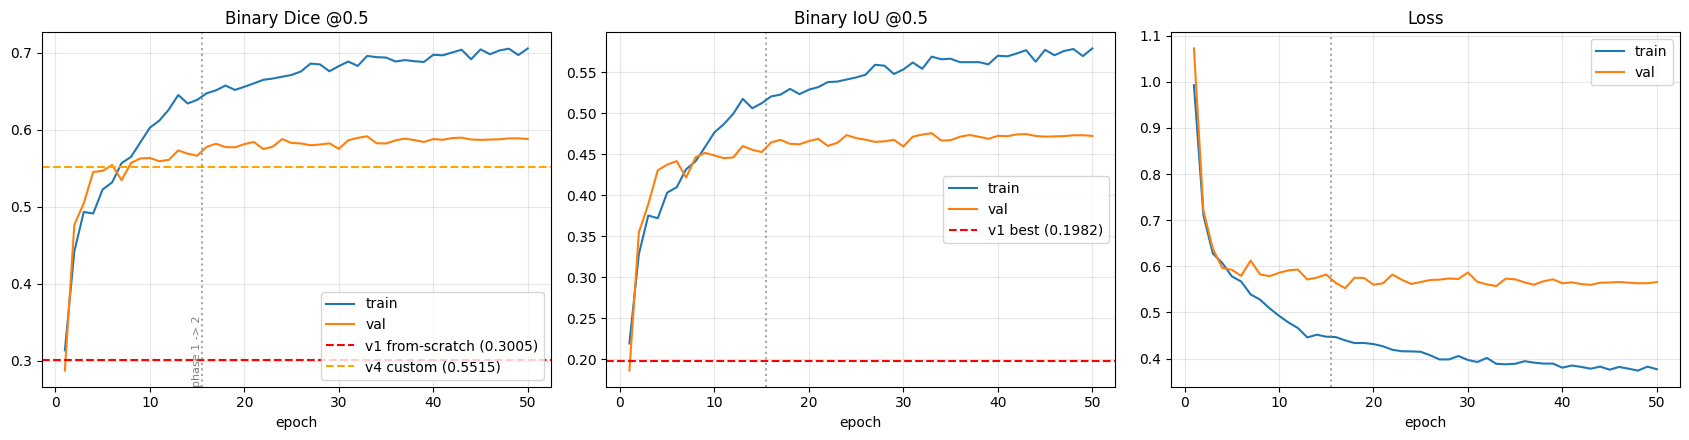

In [24]:
# ============================================================
# 20. CURVES + FIT DIAGNOSIS
# ============================================================
history_df = pd.read_csv(HISTORY_CSV)
history_df["global_epoch"] = np.arange(1, len(history_df) + 1)

assert f"val_{DICE_COL}" in history_df.columns, (
    f"Missing column val_{DICE_COL}. Found: {list(history_df.columns)}"
)

best_idx = int(history_df[f"val_{DICE_COL}"].idxmax())
best_epoch = int(history_df.loc[best_idx, "global_epoch"])
best_dice = float(history_df.loc[best_idx, f"val_{DICE_COL}"])
best_iou = float(history_df.loc[best_idx, f"val_{IOU_COL}"])
gap = float(history_df.loc[best_idx, DICE_COL]) - best_dice
best_phase = int(history_df.loc[best_idx, "phase"])

if gap < 0.03:
    verdict = "STILL UNDERFITTING -> raise PHASE2_EPOCHS/EARLY_STOP_PATIENCE, or PHASE2_LR"
elif gap > 0.15:
    verdict = "OVERFITTING -> raise WEIGHT_DECAY / DROPOUT"
else:
    verdict = "healthy fit"

print("Best epoch    :", best_epoch, "of", len(history_df), " (phase", best_phase, ")")
print("Best val Dice :", f"{best_dice:.4f}   (v1 from-scratch = {V1_DICE:.4f}, "
      f"v4 custom deep_sup = {CUSTOM_ARCH_DICE:.4f})")
print("Best val IoU  :", f"{best_iou:.4f}   (v1 = {V1_IOU:.4f})")
print("Improvement   :", f"{(best_dice / V1_DICE - 1) * 100:+.1f}% vs v1",
      f" / {(best_dice / CUSTOM_ARCH_DICE - 1) * 100:+.1f}% vs v4 custom")
print("Train-val gap :", f"{gap:+.4f}  ->", verdict)
print("(Note: this reads the CSVLogger history from single-checkpoint training;")
print(" if SWA won in 19b, the final evaluated model differs from 'best_epoch' here")
print(" -- Section 22 reports the number that actually matters.)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(history_df["global_epoch"], history_df[DICE_COL], label="train")
axes[0].plot(history_df["global_epoch"], history_df[f"val_{DICE_COL}"], label="val")
axes[0].axhline(V1_DICE, ls="--", c="r", label=f"v1 from-scratch ({V1_DICE:.4f})")
axes[0].axhline(CUSTOM_ARCH_DICE, ls="--", c="orange", label=f"v4 custom ({CUSTOM_ARCH_DICE:.4f})")
axes[0].set_title("Binary Dice @0.5")

axes[1].plot(history_df["global_epoch"], history_df[IOU_COL], label="train")
axes[1].plot(history_df["global_epoch"], history_df[f"val_{IOU_COL}"], label="val")
axes[1].axhline(V1_IOU, ls="--", c="r", label=f"v1 best ({V1_IOU:.4f})")
axes[1].set_title("Binary IoU @0.5")

axes[2].plot(history_df["global_epoch"], history_df["loss"], label="train")
axes[2].plot(history_df["global_epoch"], history_df["val_loss"], label="val")
axes[2].set_title("Loss")

for ax in axes:
    ax.axvline(PHASE_BOUNDARY_EPOCH + 0.5, ls=":", c="gray", alpha=0.7)
    ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)
axes[0].annotate("phase 1 -> 2", xy=(PHASE_BOUNDARY_EPOCH + 0.5, axes[0].get_ylim()[0]),
                 rotation=90, va="bottom", ha="right", fontsize=8, color="gray")

plt.tight_layout()
plt.savefig(RUN_DIR / f"{RUN_LABEL}_curves.png", dpi=140)
plt.show()


Best checkpoint reloaded.


Predicting val:   0%|          | 0/57 [00:00<?, ?it/s]

Validation tensor: (455, 256, 256)
 threshold   dice    iou  precision  recall
    0.1000 0.5824 0.4655     0.5557  0.8090
    0.1500 0.5859 0.4696     0.5691  0.7936
    0.2000 0.5878 0.4717     0.5786  0.7822
    0.2500 0.5893 0.4734     0.5869  0.7728
    0.3000 0.5902 0.4744     0.5947  0.7644
    0.3500 0.5908 0.4751     0.6006  0.7565
    0.4000 0.5910 0.4753     0.6061  0.7490
    0.4500 0.5912 0.4755     0.6114  0.7414
    0.5000 0.5911 0.4754     0.6166  0.7339
    0.5500 0.5908 0.4751     0.6218  0.7263
    0.6000 0.5904 0.4746     0.6271  0.7183
    0.6500 0.5896 0.4736     0.6328  0.7091
    0.7000 0.5885 0.4725     0.6389  0.6991
    0.7500 0.5869 0.4708     0.6452  0.6875
    0.8000 0.5845 0.4682     0.6526  0.6733
    0.8500 0.5800 0.4635     0.6648  0.6541
    0.9000 0.5713 0.4546     0.6792  0.6246

Best threshold : 0.45  Dice: 0.5912


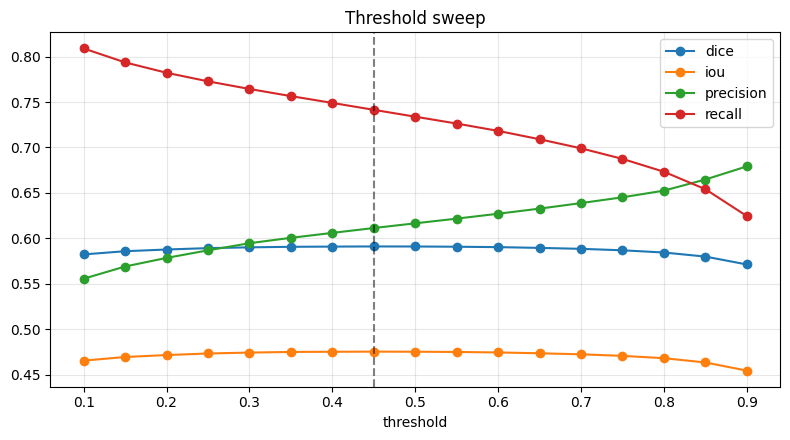

In [25]:
# ============================================================
# 21. THRESHOLD CALIBRATION
#     Reloads BEST_WEIGHTS, which Section 19b overwrites with the SWA
#     average when SWA won -- so this always calibrates against whichever
#     weights are actually going to be shipped.
# ============================================================
model.load_weights(str(BEST_WEIGHTS))
print("Best checkpoint reloaded.")

probs_list, gts_list = [], []
for xb, yb in tqdm(val_ds, desc="Predicting val"):
    out = model.predict(xb, verbose=0)
    pm = out[0] if isinstance(out, (list, tuple)) else out
    probs_list.append(pm[..., 0].astype(np.float32))
    gts_list.append(main_target(yb).numpy()[..., 0].astype(np.float32))

probs = np.concatenate(probs_list, axis=0)
gts = np.concatenate(gts_list, axis=0)
del probs_list, gts_list

assert probs.shape == gts.shape, f"shape mismatch {probs.shape} vs {gts.shape}"
assert len(probs) == len(val_df), (
    f"prediction count {len(probs)} != val rows {len(val_df)}"
)
print("Validation tensor:", probs.shape)


def sweep(probs, gts, thresholds):
    rows = []
    gt_flat = gts.reshape(gts.shape[0], -1)
    gt_sum = gt_flat.sum(1)
    pr_all = probs.reshape(probs.shape[0], -1)
    for t in thresholds:
        pr = (pr_all >= t).astype(np.float32)
        inter = (gt_flat * pr).sum(1)
        pr_sum = pr.sum(1)
        rows.append({
            "threshold": float(t),
            "dice": float(((2 * inter + 1e-6) / (gt_sum + pr_sum + 1e-6)).mean()),
            "iou": float(((inter + 1e-6) / (gt_sum + pr_sum - inter + 1e-6)).mean()),
            "precision": float(((inter + 1e-6) / (pr_sum + 1e-6)).mean()),
            "recall": float(((inter + 1e-6) / (gt_sum + 1e-6)).mean()),
        })
    return pd.DataFrame(rows)


sweep_df = sweep(probs, gts, THRESHOLD_GRID)
sweep_df.to_csv(RUN_DIR / f"{RUN_LABEL}_threshold_sweep.csv", index=False)

best_row = sweep_df.loc[sweep_df["dice"].idxmax()]
BEST_THRESHOLD = float(best_row["threshold"])

print(sweep_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
print("Best threshold :", BEST_THRESHOLD, " Dice:", f"{best_row['dice']:.4f}")

plt.figure(figsize=(8, 4.5))
for col in ("dice", "iou", "precision", "recall"):
    plt.plot(sweep_df["threshold"], sweep_df[col], marker="o", label=col)
plt.axvline(BEST_THRESHOLD, ls="--", c="k", alpha=.5)
plt.xlabel("threshold"); plt.legend(); plt.grid(alpha=.3)
plt.title("Threshold sweep")
plt.tight_layout()
plt.savefig(RUN_DIR / f"{RUN_LABEL}_threshold_sweep.png", dpi=140)
plt.show()


In [26]:
# ============================================================
# 22. FINAL EVAL + LESION-SIZE BREAKDOWN
# ============================================================
pred_bin = (probs >= BEST_THRESHOLD).astype(np.float32)
gt_flat = gts.reshape(gts.shape[0], -1)
pr_flat = pred_bin.reshape(pred_bin.shape[0], -1)

inter = (gt_flat * pr_flat).sum(1)
dice_per_image = (2 * inter + 1e-6) / (gt_flat.sum(1) + pr_flat.sum(1) + 1e-6)
iou_per_image = (inter + 1e-6) / (gt_flat.sum(1) + pr_flat.sum(1) - inter + 1e-6)

final_dice = float(dice_per_image.mean())
final_iou = float(iou_per_image.mean())

print("=" * 60)
print("FINAL VALIDATION --", RUN_LABEL)
print("=" * 60)
print(f"Threshold        : {BEST_THRESHOLD}")
print(f"Dice             : {final_dice:.4f}   (v1: {V1_DICE:.4f})")
print(f"IoU              : {final_iou:.4f}   (v1: {V1_IOU:.4f})")
print(f"Dice std         : {float(dice_per_image.std()):.4f}")
print(f"Images Dice>0.5  : {int((dice_per_image > 0.5).sum())} / {len(dice_per_image)}")
print(f"Images Dice<0.1  : {int((dice_per_image < 0.1).sum())} / {len(dice_per_image)}")

size_df = val_df.copy()
size_df["dice"] = dice_per_image
size_df["iou"] = iou_per_image
size_df["size_bin"] = pd.cut(size_df["lesion_frac"],
                             bins=SIZE_BIN_EDGES, labels=SIZE_BIN_LABELS)

breakdown = size_df.groupby("size_bin", observed=True).agg(
    images=("dice", "size"), mean_dice=("dice", "mean"), mean_iou=("iou", "mean")
).round(4)

print()
print("Performance by lesion size (compare against the previous run's table:")
print("  <1%: 0.248 | 1-5%: 0.466 | 5-15%: 0.664 | >15%: 0.781):")
print(breakdown.to_string())
breakdown.to_csv(RUN_DIR / f"{RUN_LABEL}_size_breakdown.csv")


FINAL VALIDATION -- v5_effnetb0
Threshold        : 0.45
Dice             : 0.5912   (v1: 0.3005)
IoU              : 0.4755   (v1: 0.1982)
Dice std         : 0.2842
Images Dice>0.5  : 293 / 455
Images Dice<0.1  : 34 / 455

Performance by lesion size (compare against the previous run's table:
  <1%: 0.248 | 1-5%: 0.466 | 5-15%: 0.664 | >15%: 0.781):
          images  mean_dice  mean_iou
size_bin                             
<1%           59     0.2768    0.1928
1-5%         136     0.4693    0.3383
5-15%        122     0.6949    0.5682
>15%         138     0.7539    0.6494


In [27]:
# ============================================================
# 23. SAVE ARTIFACTS + APPEND TO ABLATION LOG
# ============================================================
model.save(str(FINAL_MODEL))
model.save_weights(str(FINAL_WEIGHTS))

with open(RUN_DIR / f"{ABLATION_ARM}_architecture.json", "w") as f:
    f.write(model.to_json())

on_disk_mb = FINAL_MODEL.stat().st_size / (1024 ** 2)
weights_mb = FINAL_WEIGHTS.stat().st_size / (1024 ** 2)

with open(RUN_DIR / f"{ABLATION_ARM}_inference_config.json", "w") as f:
    json.dump({
        "ablation_arm": ABLATION_ARM, "family": "EfficientNetB0 encoder + custom decoder",
        "img_size": IMG_SIZE, "letterbox": LETTERBOX_RESIZE,
        "input_range": "[0,255] float32 (model rescales internally)",
        "best_threshold": BEST_THRESHOLD,
        "val_dice": final_dice, "val_iou": final_iou,
        "total_params": total_params, "fp32_mb": round(fp32_mb, 2),
        "keras_file_mb": round(on_disk_mb, 2),
        "used_swa": bool(swa_model is not None and swa_dice is not None
                          and swa_dice > best_dice_single),
    }, f, indent=2)

# ---- Ablation log row: flags used + overall metrics + per-size-bin Dice ----
bin_dice_by_label = {lbl: np.nan for lbl in SIZE_BIN_LABELS}
bin_n_by_label = {lbl: 0 for lbl in SIZE_BIN_LABELS}
for lbl in SIZE_BIN_LABELS:
    if lbl in breakdown.index:
        bin_dice_by_label[lbl] = float(breakdown.loc[lbl, "mean_dice"])
        bin_n_by_label[lbl] = int(breakdown.loc[lbl, "images"])

ablation_row = {
    "ablation_arm": ABLATION_ARM,
    "use_crop": USE_CROP, "use_oversample": USE_OVERSAMPLE,
    "use_elastic": USE_ELASTIC, "use_cutout": USE_CUTOUT, "use_swa": USE_SWA,
    "weight_decay": WEIGHT_DECAY, "dropout": DROPOUT,
    "total_epochs_budget": TOTAL_EPOCHS, "epochs_run": len(history_df),
    "best_epoch": best_epoch, "best_threshold": BEST_THRESHOLD,
    "val_dice_overall": round(final_dice, 4),
    "val_iou_overall": round(final_iou, 4),
    "train_val_gap": round(gap, 4),
    "dice_lt1pct": round(bin_dice_by_label["<1%"], 4) if pd.notna(bin_dice_by_label["<1%"]) else np.nan,
    "n_lt1pct": bin_n_by_label["<1%"],
    "dice_1to5pct": round(bin_dice_by_label["1-5%"], 4) if pd.notna(bin_dice_by_label["1-5%"]) else np.nan,
    "n_1to5pct": bin_n_by_label["1-5%"],
    "dice_5to15pct": round(bin_dice_by_label["5-15%"], 4) if pd.notna(bin_dice_by_label["5-15%"]) else np.nan,
    "n_5to15pct": bin_n_by_label["5-15%"],
    "dice_gt15pct": round(bin_dice_by_label[">15%"], 4) if pd.notna(bin_dice_by_label[">15%"]) else np.nan,
    "n_gt15pct": bin_n_by_label[">15%"],
    "training_minutes": round(training_seconds / 60.0, 2),
}

# Reference rows so the log always shows where you started from, even on
# the very first ablation run.
REFERENCE_ROWS = [
    {
        "ablation_arm": "REFERENCE_v1_original", "use_crop": False, "use_oversample": False,
        "use_elastic": False, "use_cutout": False, "use_swa": False,
        "weight_decay": np.nan, "dropout": np.nan, "total_epochs_budget": 55,
        "epochs_run": 55, "best_epoch": 55, "best_threshold": 0.5,
        "val_dice_overall": 0.3005, "val_iou_overall": 0.1982, "train_val_gap": 0.0093,
        "dice_lt1pct": np.nan, "n_lt1pct": np.nan, "dice_1to5pct": np.nan, "n_1to5pct": np.nan,
        "dice_5to15pct": np.nan, "n_5to15pct": np.nan, "dice_gt15pct": np.nan, "n_gt15pct": np.nan,
        "training_minutes": 236.43,
    },
    {
        "ablation_arm": "REFERENCE_mu_b_tuned_first_run", "use_crop": False, "use_oversample": False,
        "use_elastic": False, "use_cutout": False, "use_swa": False,
        "weight_decay": 1e-5, "dropout": 0.10, "total_epochs_budget": 50,
        "epochs_run": 50, "best_epoch": 20, "best_threshold": 0.4,
        "val_dice_overall": 0.5864, "val_iou_overall": 0.4741, "train_val_gap": 0.12,
        "dice_lt1pct": 0.2476, "n_lt1pct": 59, "dice_1to5pct": 0.4661, "n_1to5pct": 136,
        "dice_5to15pct": 0.6640, "n_5to15pct": 122, "dice_gt15pct": 0.7813, "n_gt15pct": 138,
        "training_minutes": np.nan,
    },
    {
        "ablation_arm": "REFERENCE_v2_all_combined_BROKEN", "use_crop": True, "use_oversample": True,
        "use_elastic": True, "use_cutout": True, "use_swa": True,
        "weight_decay": 5e-5, "dropout": 0.15, "total_epochs_budget": 50,
        "epochs_run": np.nan, "best_epoch": np.nan, "best_threshold": np.nan,
        "val_dice_overall": np.nan, "val_iou_overall": np.nan, "train_val_gap": np.nan,
        "dice_lt1pct": 0.0958, "n_lt1pct": 59, "dice_1to5pct": 0.3257, "n_1to5pct": 136,
        "dice_5to15pct": 0.6086, "n_5to15pct": 122, "dice_gt15pct": 0.7358, "n_gt15pct": 138,
        "training_minutes": np.nan,
    },
    {
        "ablation_arm": "REFERENCE_v4_custom_deepsup", "use_crop": True, "use_oversample": True,
        "use_elastic": True, "use_cutout": True, "use_swa": True,
        "weight_decay": 3e-5, "dropout": 0.12, "total_epochs_budget": 50,
        "epochs_run": 44, "best_epoch": 30, "best_threshold": 0.55,
        "val_dice_overall": 0.5515, "val_iou_overall": 0.4333, "train_val_gap": 0.0332,
        "dice_lt1pct": 0.2623, "n_lt1pct": 59, "dice_1to5pct": 0.4359, "n_1to5pct": 136,
        "dice_5to15pct": 0.6354, "n_5to15pct": 122, "dice_gt15pct": 0.7150, "n_gt15pct": 138,
        "training_minutes": 120.21,
    },
]

if ABLATION_CSV.exists():
    log = pd.read_csv(ABLATION_CSV)
    log = log[log["ablation_arm"] != ABLATION_ARM]
    log = pd.concat([log, pd.DataFrame([ablation_row])], ignore_index=True)
    existing_refs = set(log["ablation_arm"])
    missing_refs = [r for r in REFERENCE_ROWS if r["ablation_arm"] not in existing_refs]
    if missing_refs:
        log = pd.concat([pd.DataFrame(missing_refs), log], ignore_index=True)
else:
    log = pd.DataFrame(REFERENCE_ROWS + [ablation_row])

log.to_csv(ABLATION_CSV, index=False)

print("Saved:", FINAL_MODEL, f"({on_disk_mb:.2f} MB on disk)")
print()
print("=" * 130)
print("ABLATION LOG --", ABLATION_CSV)
print("=" * 130)
cols = ["ablation_arm", "use_crop", "use_oversample", "use_elastic", "use_cutout",
        "val_dice_overall", "dice_lt1pct", "dice_1to5pct", "dice_5to15pct", "dice_gt15pct"]
print(log[cols].to_string(index=False))
print()
print("Compare this row against the four reference rows above: v1 (from-scratch),")
print("the first mu_b_tuned run, the broken v2 run, and the v4 custom deep_sup run.")
print("The question that matters: did the pretrained encoder move val_dice_overall AND")
print("the size-bin columns, not just the headline number.")


Saved: /kaggle/working/Segmentation Output/run_v5_effnetb0/v5_effnetb0_final.keras (73.86 MB on disk)

ABLATION LOG -- /kaggle/working/Segmentation Output/ablation_results.csv
                    ablation_arm  use_crop  use_oversample  use_elastic  use_cutout  val_dice_overall  dice_lt1pct  dice_1to5pct  dice_5to15pct  dice_gt15pct
           REFERENCE_v1_original     False           False        False       False            0.3005          NaN           NaN            NaN           NaN
  REFERENCE_mu_b_tuned_first_run     False           False        False       False            0.5864       0.2476        0.4661         0.6640        0.7813
REFERENCE_v2_all_combined_BROKEN      True            True         True        True               NaN       0.0958        0.3257         0.6086        0.7358
     REFERENCE_v4_custom_deepsup      True            True         True        True            0.5515       0.2623        0.4359         0.6354        0.7150
                     v5_effnetb0  

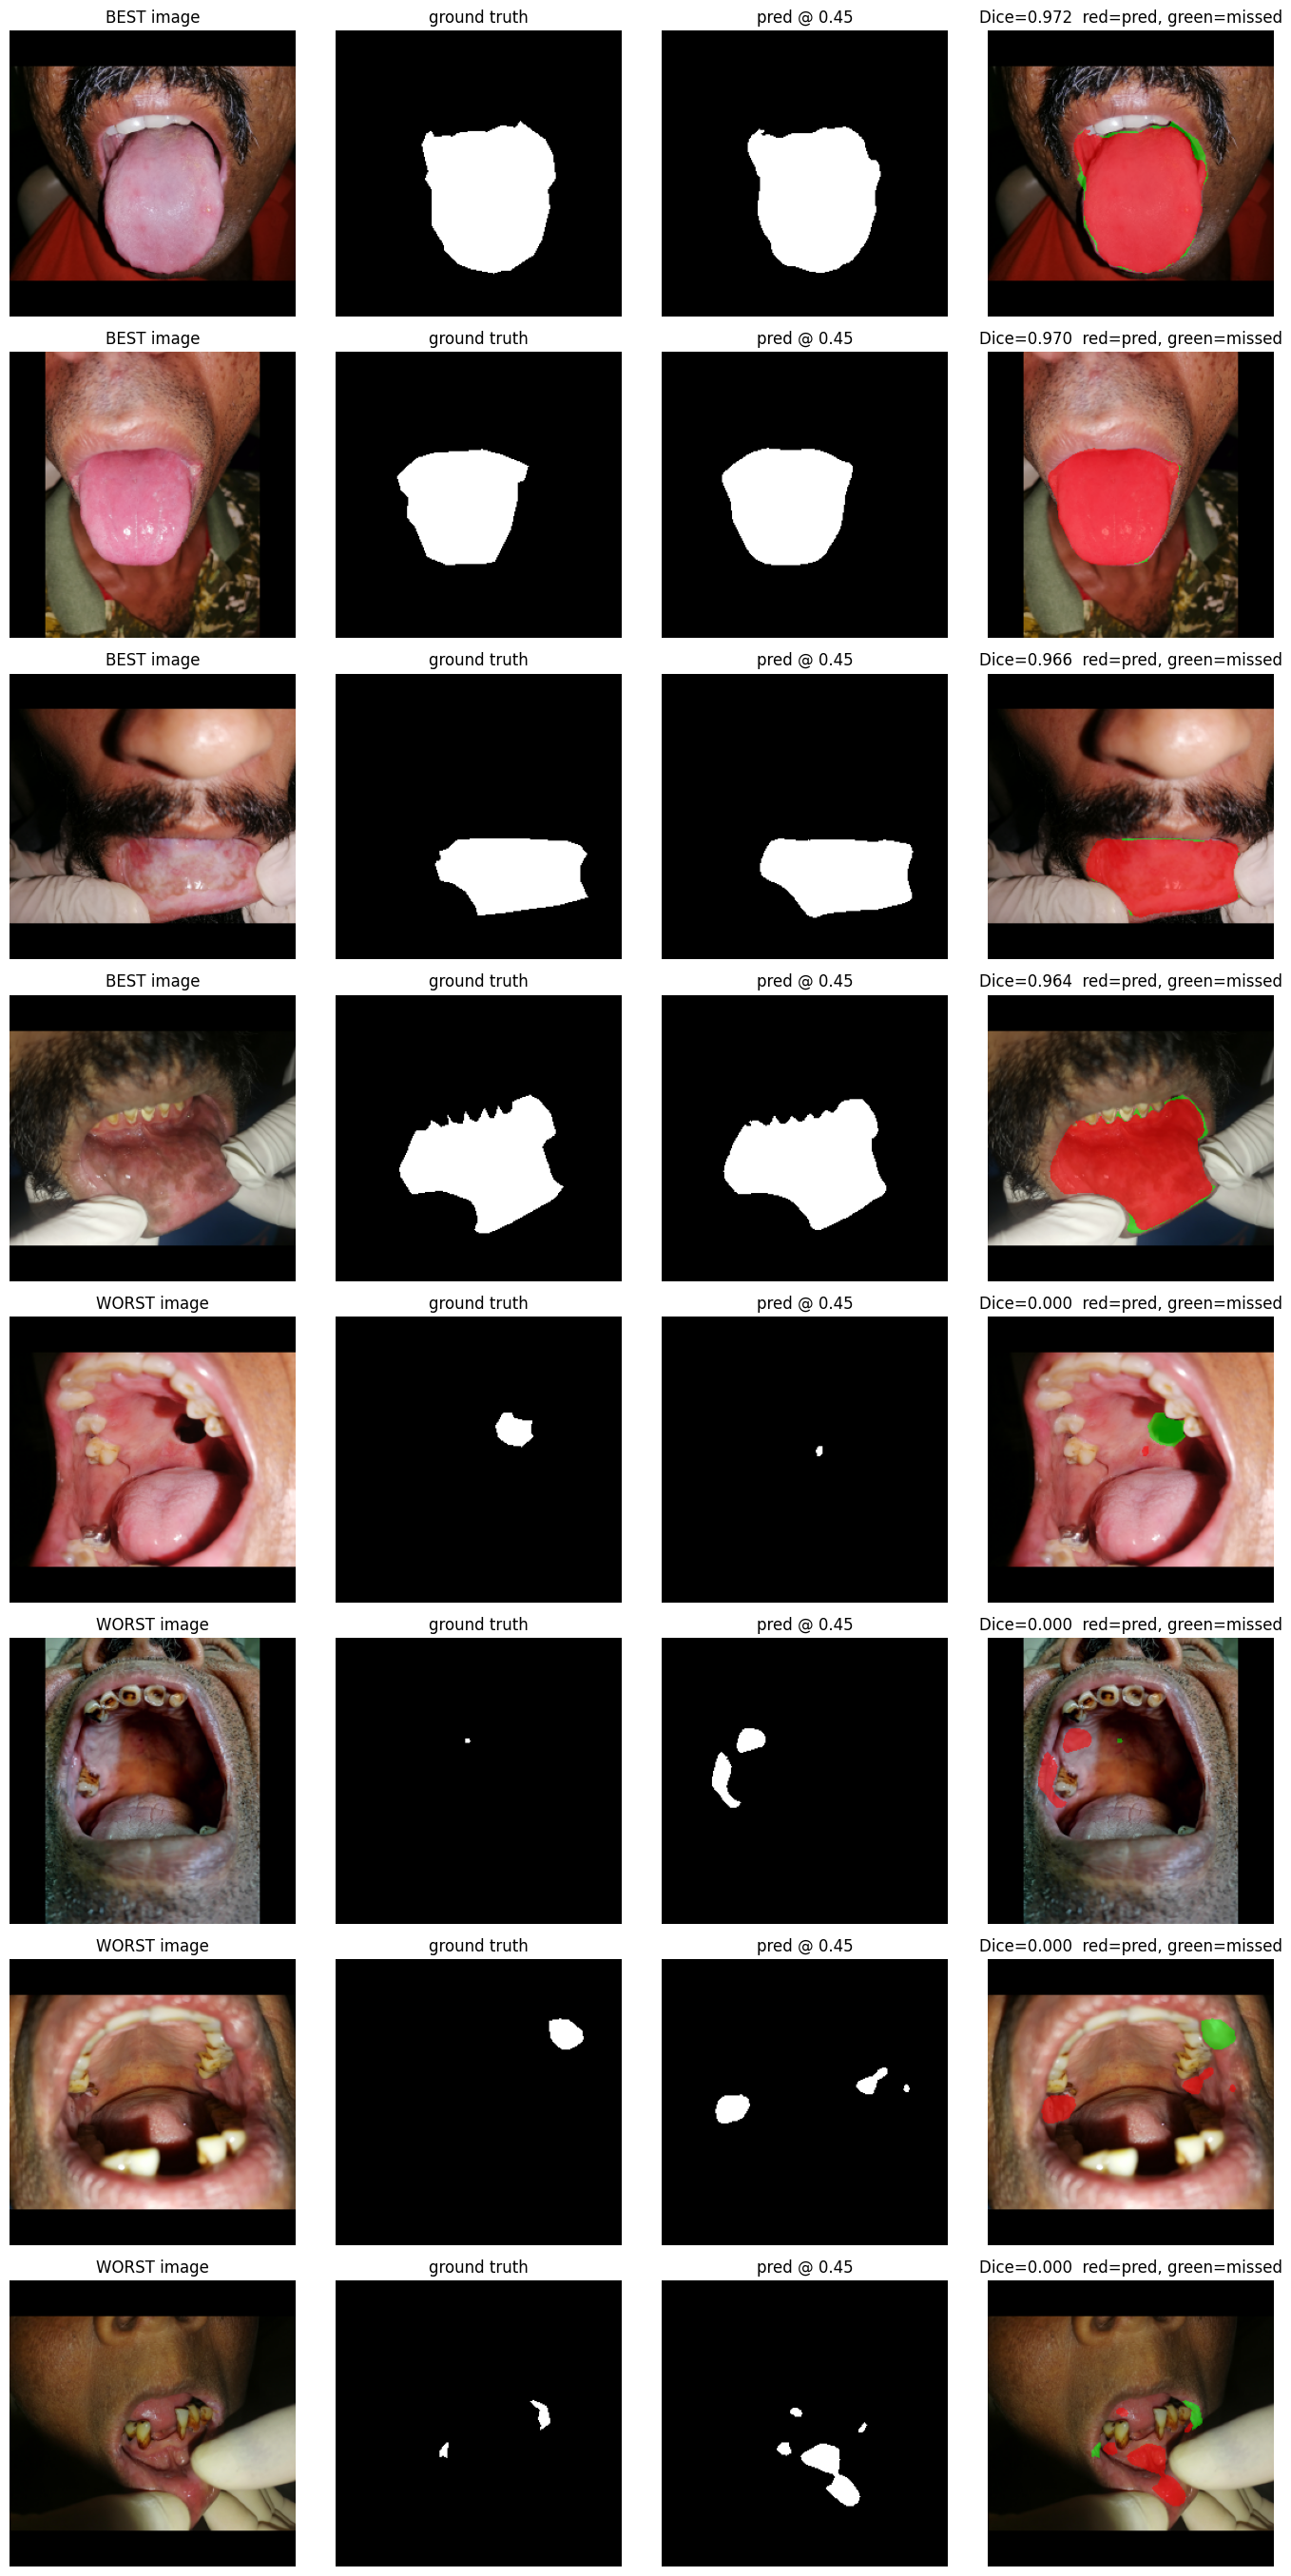

In [28]:
# ============================================================
# 24. QUALITATIVE PREDICTIONS (4 best + 4 worst)
# ============================================================
SEG_DIR = RUN_DIR / "final_segmented"
SEG_DIR.mkdir(parents=True, exist_ok=True)

order = np.argsort(-dice_per_image)
show_idx = list(order[:4]) + list(order[-4:])

fig, axes = plt.subplots(len(show_idx), 4, figsize=(14, 3.4 * len(show_idx)))

for r, idx in enumerate(show_idx):
    idx = int(idx)
    row = val_df.iloc[idx]

    img = safe_imread(row["image_path"], cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = (letterbox(img, IMG_SIZE, cv2.INTER_AREA) if LETTERBOX_RESIZE
           else cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))

    gt = (gts[idx] * 255).astype(np.uint8)
    pm = (pred_bin[idx] * 255).astype(np.uint8)

    ov = img.copy()
    hit = pm > 0
    miss = (gt > 0) & (pm == 0)
    ov[hit] = (0.45 * ov[hit] + 0.55 * np.array([255, 0, 0])).astype(np.uint8)
    ov[miss] = (0.45 * ov[miss] + 0.55 * np.array([0, 255, 0])).astype(np.uint8)

    tag = "BEST" if r < 4 else "WORST"
    axes[r, 0].imshow(img);             axes[r, 0].set_title(f"{tag} image")
    axes[r, 1].imshow(gt, cmap="gray"); axes[r, 1].set_title("ground truth")
    axes[r, 2].imshow(pm, cmap="gray"); axes[r, 2].set_title(f"pred @ {BEST_THRESHOLD}")
    axes[r, 3].imshow(ov)
    axes[r, 3].set_title(f"Dice={dice_per_image[idx]:.3f}  red=pred, green=missed")
    for c in range(4):
        axes[r, c].axis("off")

    cv2.imwrite(str(SEG_DIR / f"{row['image_id']}_pred.png"),
                cv2.cvtColor(ov, cv2.COLOR_RGB2BGR))

plt.tight_layout()
plt.savefig(RUN_DIR / f"{RUN_LABEL}_predictions.png", dpi=140)
plt.show()


In [29]:
# ============================================================
# 25. FINAL AUDIT
# ============================================================
required = [
    BEST_WEIGHTS, FINAL_MODEL, FINAL_WEIGHTS, HISTORY_CSV,
    PHASE1_WEIGHTS, PHASE2_WEIGHTS,
    RUN_DIR / f"{RUN_LABEL}_architecture.json",
    RUN_DIR / f"{RUN_LABEL}_inference_config.json",
    RUN_DIR / f"{RUN_LABEL}_threshold_sweep.csv",
    RUN_DIR / f"{RUN_LABEL}_size_breakdown.csv",
    RUN_DIR / f"{RUN_LABEL}_curves.png",
    RUN_DIR / f"{RUN_LABEL}_predictions.png",
    RUN_DIR / "jpeg_integrity_scan.csv",
    ABLATION_CSV,
]
missing = [str(p) for p in required if not p.exists()]
print("Missing artifacts:", missing if missing else "none")
assert not missing, "STOP: artifacts missing."

_swa_won = bool(USE_SWA and swa_model is not None and swa_dice is not None
               and best_dice_single is not None and swa_dice > best_dice_single)
_winning_phase = "SWA (phase 2 average)" if _swa_won else (
    "phase 2 (fine-tuned)" if phase2_dice >= phase1_dice else "phase 1 (frozen encoder)")

print()
print("Audit")
print("  Architecture family    : EfficientNetB0 encoder + custom Mobile-UNet decoder")
print("  External backbone      : EfficientNetB0 (tf.keras.applications)")
print("  Pretrained weights     : YES -- ImageNet")
print("  Transfer learning      : YES -- this notebook deliberately drops the")
print("                            no-transfer-learning constraint used everywhere else")
print("                            in this series. Say so wherever this result is reported.")
print("  Run label               :", RUN_LABEL)
print("  Image size             :", IMG_SIZE, " batch:", BATCH_SIZE, "x", GRAD_ACCUM_STEPS)
print("  Phase 1 (frozen)        :", phase1_epochs_run, "epochs @ LR", PHASE1_LR,
      " trainable params:", f"{trainable_phase1:,}")
print("  Phase 2 (fine-tuned)    :", phase2_epochs_run, "epochs @ LR", PHASE2_LR,
      " trainable params:", f"{trainable_phase2:,}", "(BatchNorm layers kept frozen)")
print("  Winning checkpoint      :", _winning_phase)
print("  use_crop (scale-consist):", USE_CROP, " prob:", TRAIN_CROP_PROB)
print("  use_oversample          :", USE_OVERSAMPLE, SIZE_BIN_TARGET_FREQ if USE_OVERSAMPLE else "")
print("  use_elastic / use_cutout:", USE_ELASTIC, "/", USE_CUTOUT)
print("  weight_decay / dropout  :", WEIGHT_DECAY, "/", DROPOUT)
print("  SWA requested / applied :", USE_SWA, "/", _swa_won, "(phase 2 checkpoints only)")
print("  Attention gates        :", USE_GATES)
print("  CBAM bottleneck        :", USE_CBAM)
print("  ASPP bottleneck        :", USE_ASPP)
print("  Deep supervision       :", USE_DEEP_SUP)
print("  Layer-name registry    : ACTIVE for the decoder (duplicate names impossible)")
print("  Optimizer              : AdamW warmup+cosine per phase (no ReduceLROnPlateau)")
print("  Loss                   : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)")
print("  Custom objects         : registered (save/load safe)")
print("  Resize                 :", "letterbox" if LETTERBOX_RESIZE else "square squash")
print("  Split                  : stratified by lesion area, leak-checked")
print("  Threshold              : calibrated ->", BEST_THRESHOLD)
print("  Epoch budget           :", TOTAL_EPOCHS, " (epochs actually run:", len(history_df), ")")
print()
print(f"  SIZE    : {total_params:,} params total "
      f"({encoder_params:,} encoder + {decoder_params:,} decoder), "
      f"{fp32_mb:.2f} MB FP32, {on_disk_mb:.2f} MB on disk")
print(f"  RESULT  : val Dice {final_dice:.4f}  val IoU {final_iou:.4f}")
print(f"            reference points -- v1 from-scratch: {V1_DICE:.4f}, "
      f"v4 custom deep_sup (no pretrain): {CUSTOM_ARCH_DICE:.4f}")
print()
print("Size breakdown this run (compare against the reference rows in ablation_results.csv):")
print(breakdown.to_string())
print()
print("This run's row has been appended to:", ABLATION_CSV)
print("The comparison that matters: did dice_lt1pct through dice_gt15pct all move up")
print("together, not just the headline val_dice_overall number.")


Missing artifacts: none

Audit
  Architecture family    : EfficientNetB0 encoder + custom Mobile-UNet decoder
  External backbone      : EfficientNetB0 (tf.keras.applications)
  Pretrained weights     : YES -- ImageNet
  Transfer learning      : YES -- this notebook deliberately drops the
                            no-transfer-learning constraint used everywhere else
                            in this series. Say so wherever this result is reported.
  Run label               : v5_effnetb0
  Image size             : 256  batch: 8 x 1
  Phase 1 (frozen)        : 15 epochs @ LR 0.0003  trainable params: 2,343,709
  Phase 2 (fine-tuned)    : 35 epochs @ LR 1e-05  trainable params: 6,309,241 (BatchNorm layers kept frozen)
  Winning checkpoint      : phase 2 (fine-tuned)
  use_crop (scale-consist): True  prob: 0.35
  use_oversample          : True {'<1%': 0.28, '1-5%': 0.27, '5-15%': 0.23, '>15%': 0.22}
  use_elastic / use_cutout: True / True
  weight_decay / dropout  : 1.5e-05 / 0.1
  SWA

## What to do with the result

Section 25's audit prints this run's overall Dice, IoU, and the full lesion-size
breakdown, and appends one row to `ablation_results.csv` alongside reference rows for
v1 (from-scratch), the first `mu_b_tuned` run, the broken v2 run, and the v4 custom
`deep_sup` run (no pretraining, 0.5515 overall). **The comparison that matters is whether
the pretrained encoder moved every size bin, not just the headline number** — a pretrained
encoder that only helps large lesions (which were already doing fine) isn't the win you're
looking for.

**If Section 20 says STILL UNDERFITTING** (train/val gap < 0.03) after phase 2: the
fine-tuning phase isn't using its budget. Raise `PHASE2_EPOCHS` and/or `EARLY_STOP_PATIENCE`
in Section 2, or raise `PHASE2_LR` slightly (e.g. 1e-5 → 2e-5) — fine-tuning a pretrained
encoder that's barely moving usually means the LR is too conservative for the epoch budget,
not that the model lacks capacity.

**If it says OVERFITTING** (gap > 0.15): raise `WEIGHT_DECAY` and `DROPOUT` in Section 2.
A pretrained encoder generalizes better than a from-scratch one on a small dataset, so this
is less likely here than in the earlier custom-architecture runs, but still worth checking.

**If phase 1 (frozen) beat phase 2 (fine-tuned)** — the audit prints which phase won —
that means fine-tuning the encoder made things worse. Two ways to fix it: lower `PHASE2_LR`
further (it may still be too aggressive for 1,800 images), or skip phase 2 entirely next
time (`PHASE2_EPOCHS = 0`) and ship the frozen-encoder result, which is a perfectly valid
outcome — not every dataset benefits from unfreezing.

**If the size-breakdown table still shows `<1%` and `1-5%` lagging far behind `>15%`**
even with a pretrained encoder: that's a meaningful signal. It suggests the ceiling on
very small lesions isn't really about "from scratch vs. pretrained" at all — it may be
close to the limit of what ~1,800 images and this annotation quality can support for
sub-1%-area objects, regardless of architecture. At that point the next lever is more
data or higher input resolution specifically for small lesions (patch-based inference
around candidate regions), not another training-recipe or architecture change.

**On the dropped constraint**: if this result gets used anywhere that stated "no transfer
learning" as a requirement (a report, a thesis claim, a comparison table), that claim is
no longer true for this run specifically. Keep the from-scratch runs (v1, v4) as the
"no transfer learning" comparison point, and label this one clearly as using a pretrained
encoder if both get reported together.
